<a href="https://colab.research.google.com/github/bhavishya-boost/Data-Science-Visualization-Lab-Experiment-/blob/main/BHAVISHYA_9th_Data_Visualisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DATA VISUALISATION**

,total_item_price,distinct_orders
customer_state,,
SP,"5,427,808.00",16188
RJ,"1,669,256.00",5079
MG,"1,508,676.00",4378
RS,"829,301.00",2184
PR,"711,489.00",1905
SC,"464,679.00",1406
BA,"442,008.00",1275
DF,"288,017.00",844
GO,"276,987.00",740


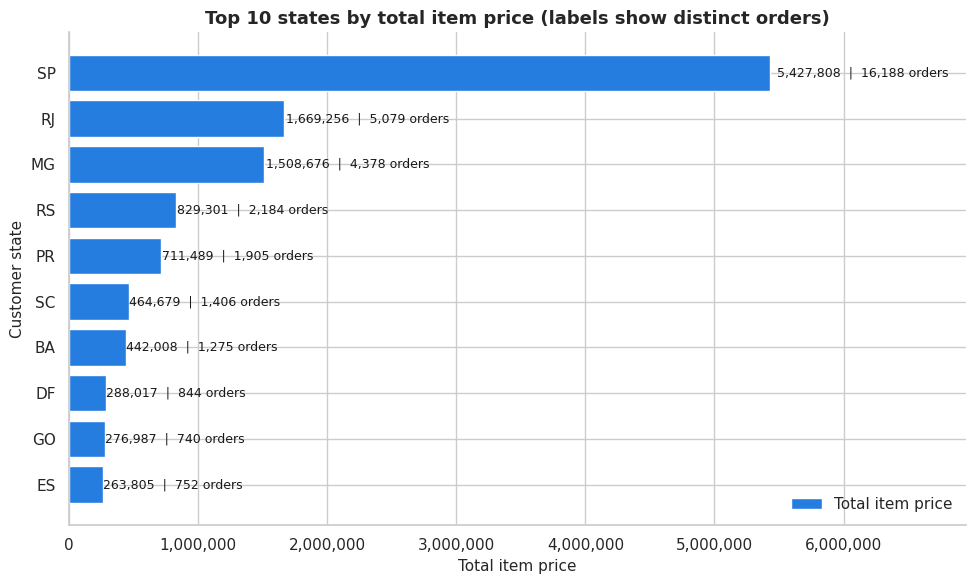

In [80]:
#Q1
state_tot = (items.groupby('customer_state')
                  .agg(total_item_price=('price', 'sum'), distinct_orders=('order_id', 'nunique')))
top10 = state_tot.nlargest(10, 'total_item_price')
display(top10)

fig, ax = plt.subplots(figsize=(10, 6))
rev = top10.iloc[::-1]
bars = ax.barh(rev.index, rev['total_item_price'], color=PAL[0], label='Total item price')
for b, n in zip(bars, rev['distinct_orders']):
    ax.text(b.get_width() * 1.01, b.get_y() + b.get_height() / 2,
            f'{b.get_width():,.0f}  |  {n:,} orders', va='center', fontsize=9, color=INK)
ax.set_xlim(0, top10['total_item_price'].max() * 1.28)
ax.xaxis.set_major_formatter(thousands)
ax.set_xlabel('Total item price'); ax.set_ylabel('Customer state')
ax.set_title('Top 10 states by total item price (labels show distinct orders)')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

,total_item_price
Toys,"9,795,863.00"
Garden Tools,"413,361.00"
Furniture Decor,"340,719.00"
Bed Bath Table,"252,201.00"
Health Beauty,"245,294.00"
Watches Gifts,"243,865.00"
Telephony,"233,747.00"
Sports Leisure,"226,183.00"


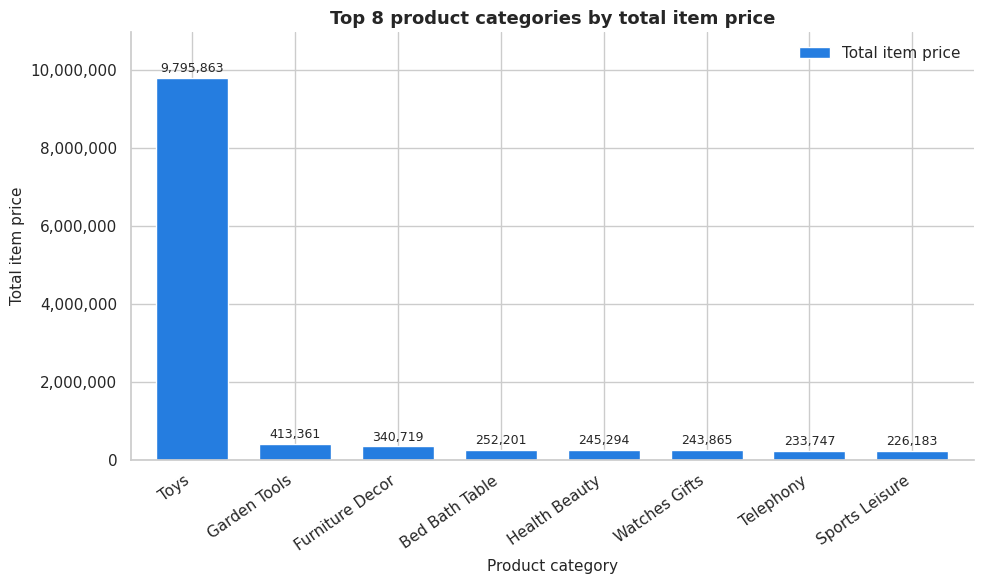

In [81]:
#Q2
cat_tot = items.groupby('category')['price'].sum().nlargest(8)
cat_tot.index = nice(cat_tot.index)
display(cat_tot.to_frame('total_item_price'))

ax = cat_tot.plot(kind='bar', figsize=(10, 6), color=PAL[0], width=0.7, label='Total item price')
ax.bar_label(ax.containers[0], labels=[f'{v:,.0f}' for v in cat_tot], fontsize=9, padding=2)
ax.set_title('Top 8 product categories by total item price')
ax.set_xlabel('Product category'); ax.set_ylabel('Total item price')
ax.yaxis.set_major_formatter(thousands)
plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
ax.set_ylim(0, cat_tot.max() * 1.12)
ax.legend()
plt.tight_layout(); plt.show()

Months with no payments in range: ['2016-11']


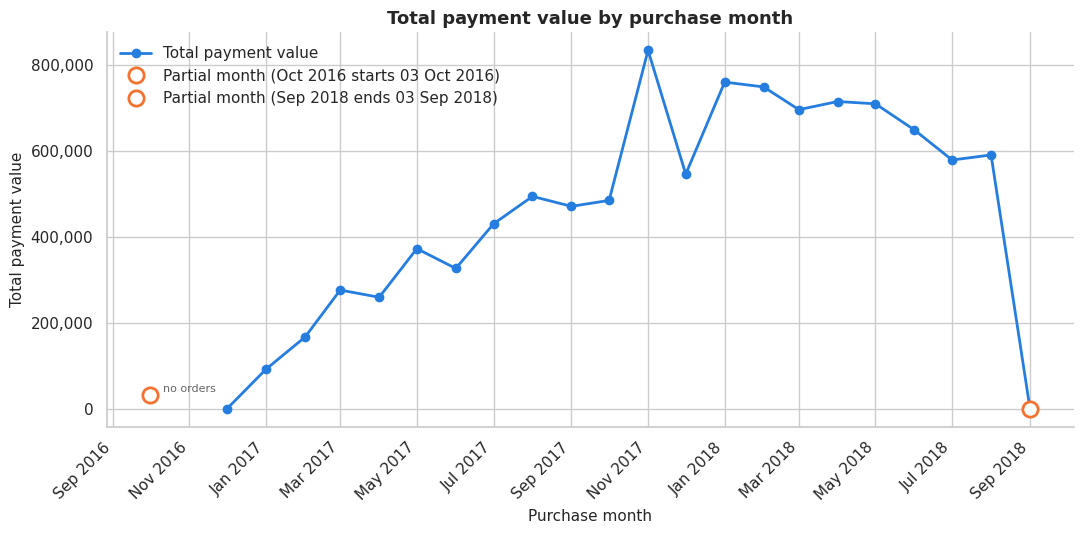

In [82]:
#Q3
monthly_pay = pay.groupby('month')['payment_value'].sum()
monthly_pay = full_months(monthly_pay)
x = monthly_pay.index.to_timestamp()
print('Months with no payments in range:', [str(p) for p in monthly_pay.index[monthly_pay.isna()]])

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(x, monthly_pay.values, marker='o', color=PAL[0], lw=2, label='Total payment value')
for p, note in PARTIAL.items():
    ax.plot(p.to_timestamp(), monthly_pay[p], 'o', ms=11, mfc='white', mec=PAL[1], mew=2,
            label=f'Partial month ({p.strftime("%b %Y")} {note})')
for p in monthly_pay.index[monthly_pay.isna()]:
    ax.annotate('no orders', (p.to_timestamp(), 0), xytext=(0, 12), textcoords='offset points',
                ha='center', fontsize=8, color=MUTED)
ax.set_title('Total payment value by purchase month')
ax.set_xlabel('Purchase month'); ax.set_ylabel('Total payment value')
ax.yaxis.set_major_formatter(thousands); month_axis(ax)
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

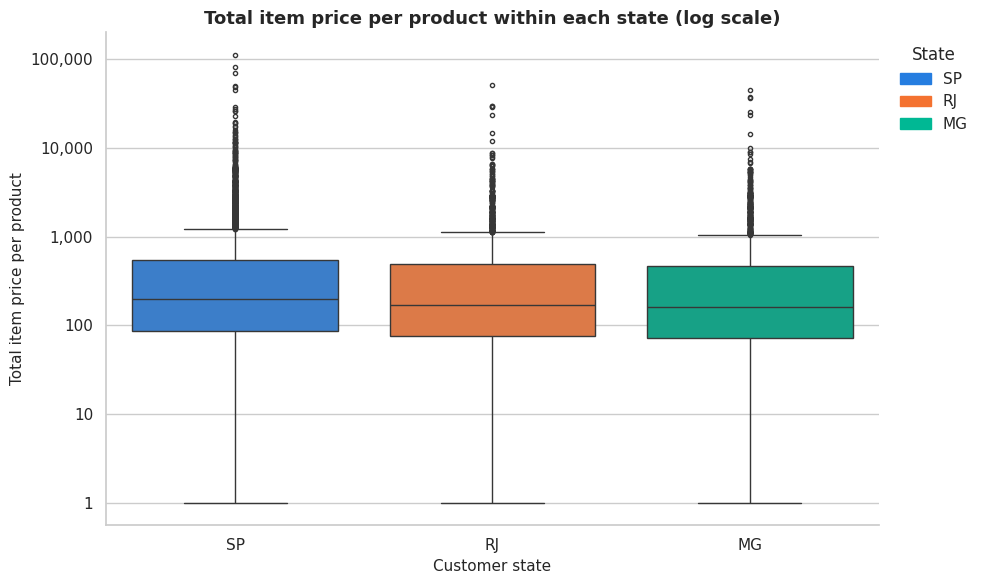

,count,min,25%,50%,75%,max
customer_state,,,,,,
SP,"8,939.00",1.00,86.00,198.00,543.50,"112,089.00"
RJ,"3,442.00",1.00,76.00,171.00,496.00,"50,966.00"
MG,"3,030.00",1.00,72.00,161.00,462.75,"44,449.00"


In [83]:
#Q21
REGIONS = ['SP', 'RJ', 'MG']
region_extracts = {s: customers[customers['customer_state'] == s] for s in REGIONS}
reg_customers = pd.concat(region_extracts.values(), ignore_index=True)
assert reg_customers['customer_id'].is_unique and len(reg_customers) == customers['customer_state'].isin(REGIONS).sum()

reg_items = (items.drop(columns=['customer_state', 'customer_city'])
                  .merge(reg_customers[['customer_id', 'customer_state']], on='customer_id',
                         how='inner', validate='many_to_one'))
state_prod = (reg_items.groupby(['customer_state', 'product_id'])['price'].sum()
                       .rename('total_item_price').reset_index())

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=state_prod, x='customer_state', y='total_item_price', order=REGIONS, hue='customer_state',
            hue_order=REGIONS, palette=PAL[:3], legend=False, fliersize=3, ax=ax)
ax.set_yscale('log'); ax.yaxis.set_major_formatter(thousands)
ax.set_title('Total item price per product within each state (log scale)')
ax.set_xlabel('Customer state'); ax.set_ylabel('Total item price per product')
ax.legend(handles=[Patch(color=PAL[i], label=s) for i, s in enumerate(REGIONS)], title='State',
          bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()
display(state_prod.groupby('customer_state')['total_item_price']
        .describe()[['count', 'min', '25%', '50%', '75%', 'max']].reindex(REGIONS))

payment_type,credit_card,wallet,voucher,debit_card
customer_state,,,,
SP,12021,3004,919,244
RJ,3824,867,327,61
MG,3216,902,210,50
RS,1511,567,92,14
PR,1382,423,84,16


payment_type,credit_card %,wallet %,voucher %,debit_card %
customer_state,,,,
SP,74.30,18.60,5.70,1.50
RJ,75.30,17.10,6.40,1.20
MG,73.50,20.60,4.80,1.10
RS,69.20,26.00,4.20,0.60
PR,72.50,22.20,4.40,0.80


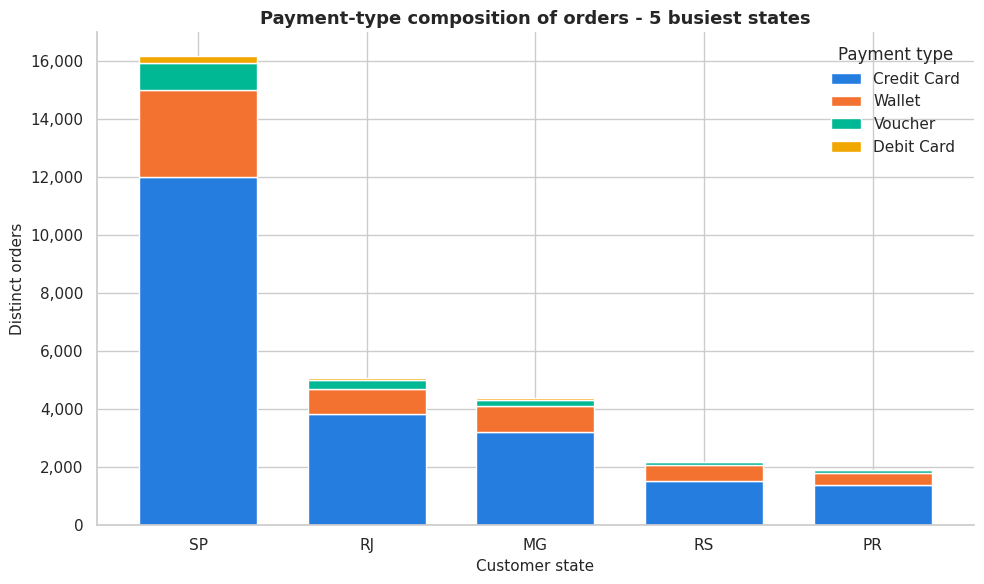

In [84]:
#Q4
top5 = orders['customer_state'].value_counts().head(5).index.tolist()
comp = (pay[pay['customer_state'].isin(top5)]
        .groupby(['customer_state', 'payment_type'])['order_id'].nunique()
        .unstack(fill_value=0).reindex(index=top5, columns=PAY_ORDER, fill_value=0))
display(comp)
display((comp.div(comp.sum(axis=1), axis=0) * 100).round(1).add_suffix(' %'))

ax = comp.plot(kind='bar', stacked=True, figsize=(10, 6), color=[PAY_COLORS[c] for c in comp.columns],
               edgecolor='white', width=0.7)
ax.set_title('Payment-type composition of orders - 5 busiest states')
ax.set_xlabel('Customer state'); ax.set_ylabel('Distinct orders')
ax.yaxis.set_major_formatter(thousands)
plt.setp(ax.get_xticklabels(), rotation=0)
ax.legend(title='Payment type', labels=nice(comp.columns))
plt.tight_layout(); plt.show()

,mean_item_price,mean_shipping_charges
category,,
toys,341.35,44.70
health_beauty,236.31,41.97
bed_bath_table,266.03,42.28
sports_leisure,281.32,43.06
computers_accessories,272.54,41.90
furniture_decor,457.96,43.96
housewares,289.98,42.94
watches_gifts,498.70,42.11


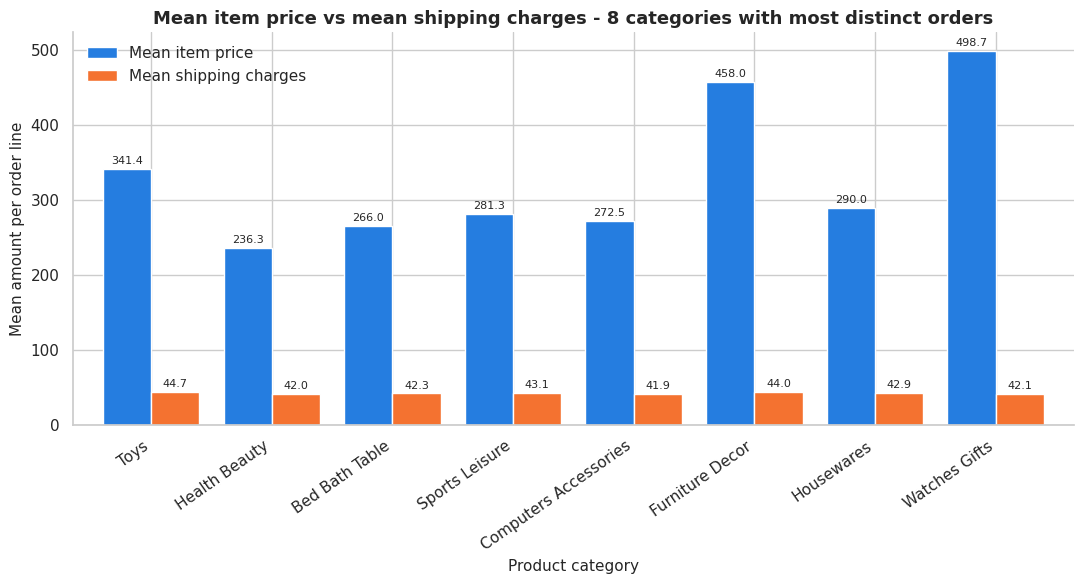

In [85]:
#Q6
top8 = items.groupby('category')['order_id'].nunique().nlargest(8).index.tolist()
means = (items[items['category'].isin(top8)].groupby('category')
         .agg(mean_item_price=('price', 'mean'), mean_shipping_charges=('shipping_charges', 'mean'))
         .reindex(top8))
display(means)

plot_df = means.copy(); plot_df.index = nice(plot_df.index)
ax = plot_df.plot(kind='bar', figsize=(11, 6), color=[PAL[0], PAL[1]], width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', fontsize=8, padding=2)
ax.set_title('Mean item price vs mean shipping charges - 8 categories with most distinct orders')
ax.set_xlabel('Product category'); ax.set_ylabel('Mean amount per order line')
plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
ax.legend(labels=['Mean item price', 'Mean shipping charges'])
plt.tight_layout(); plt.show()

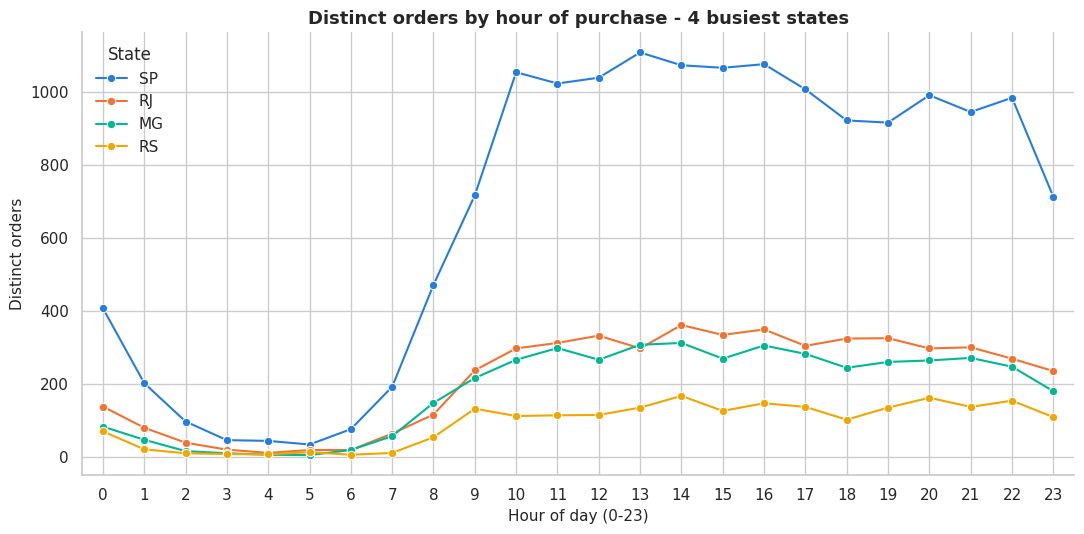

In [86]:
#Q5
top4 = orders['customer_state'].value_counts().head(4).index.tolist()
hourly = (orders[orders['customer_state'].isin(top4)]
          .groupby(['customer_state', 'hour'])['order_id'].nunique())
grid = pd.MultiIndex.from_product([top4, range(24)], names=['customer_state', 'hour'])
hourly = hourly.reindex(grid, fill_value=0).rename('distinct_orders').reset_index()

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.lineplot(data=hourly, x='hour', y='distinct_orders', hue='customer_state', hue_order=top4,
             palette=PAL[:4], marker='o', errorbar=None, ax=ax)
ax.set_xticks(range(24)); ax.set_xlim(-0.5, 23.5)
ax.set_title('Distinct orders by hour of purchase - 4 busiest states')
ax.set_xlabel('Hour of day (0-23)'); ax.set_ylabel('Distinct orders')
ax.legend(title='State')
plt.tight_layout(); plt.show()

customers: 38,279 | max orders per customer: 1


,total_item_price
count,"38,279.00"
mean,342.53
std,560.29
min,1.00
25%,60.00
50%,137.00
75%,399.00
90%,820.00
99%,"2,899.00"
max,"6,729.00"


skewness = 3.76


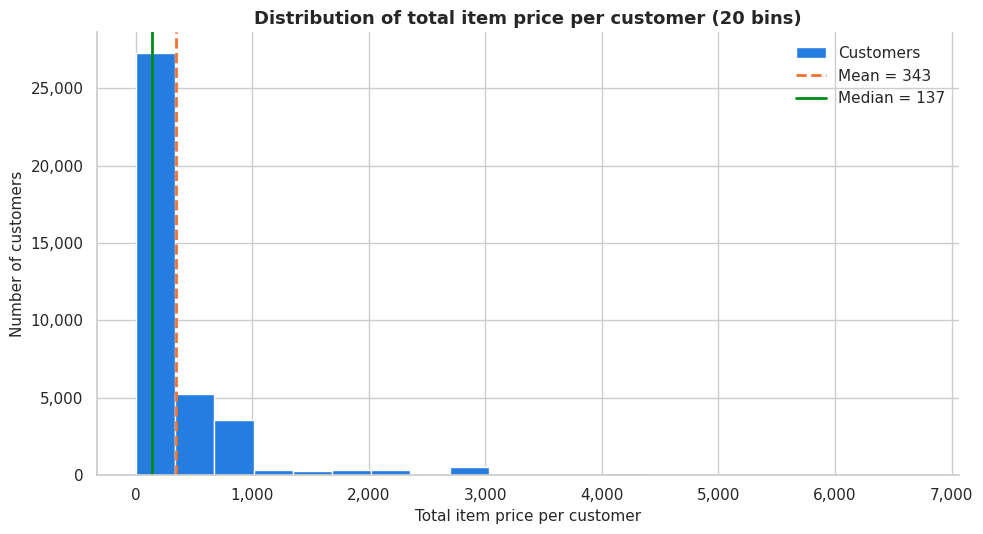

In [87]:
#Q7
cust_total = items.groupby('customer_id')['price'].sum()      # one observation per customer
orders_per_customer = orders.groupby('customer_id')['order_id'].nunique()
print(f'customers: {len(cust_total):,} | max orders per customer: {orders_per_customer.max()}')

display(cust_total.describe(percentiles=[.25, .5, .75, .9, .99]).to_frame('total_item_price'))
print(f'skewness = {cust_total.skew():.2f}')

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.hist(cust_total, bins=20, color=PAL[0], edgecolor='white', label='Customers')
ax.axvline(cust_total.mean(), color=PAL[1], ls='--', lw=2, label=f'Mean = {cust_total.mean():,.0f}')
ax.axvline(cust_total.median(), color=PAL[5], ls='-', lw=2, label=f'Median = {cust_total.median():,.0f}')
ax.set_title('Distribution of total item price per customer (20 bins)')
ax.set_xlabel('Total item price per customer'); ax.set_ylabel('Number of customers')
ax.xaxis.set_major_formatter(thousands); ax.yaxis.set_major_formatter(thousands)
ax.legend()
plt.tight_layout(); plt.show()

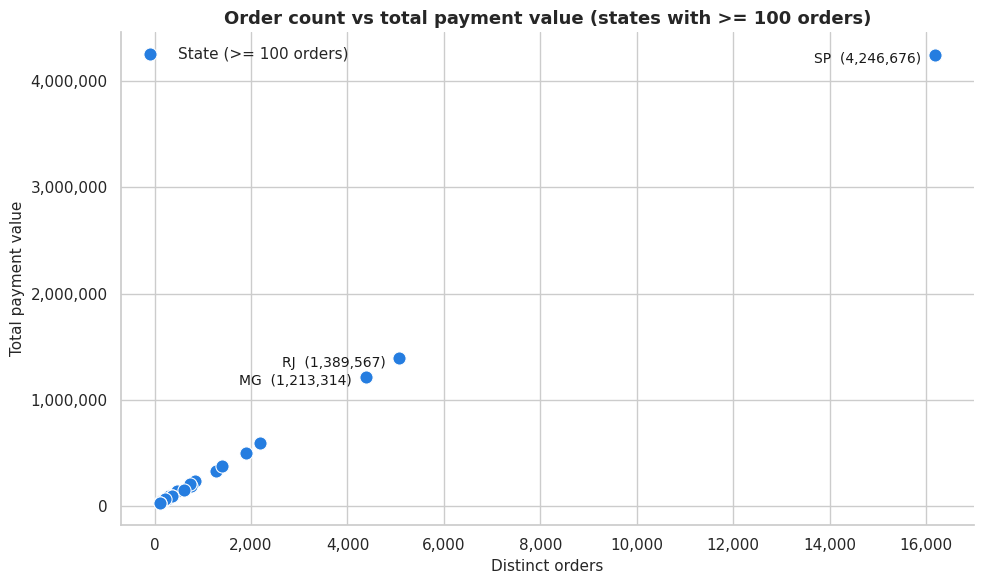

,distinct_orders,total_payment
customer_state,,
SP,16188,"4,246,676.00"
RJ,5079,"1,389,567.00"
MG,4378,"1,213,314.00"


In [88]:
#Q8
state_stats = (pay.groupby('customer_state')
                  .agg(distinct_orders=('order_id', 'nunique'), total_payment=('payment_value', 'sum')))
big = state_stats[state_stats['distinct_orders'] >= 100]
top3 = big.nlargest(3, 'total_payment')

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=big, x='distinct_orders', y='total_payment', s=90, color=PAL[0],
                edgecolor='white', label='State (>= 100 orders)', ax=ax)
for st, r in top3.iterrows():
    ax.annotate(f'{st}  ({r.total_payment:,.0f})', (r.distinct_orders, r.total_payment),
                xytext=(-10, -6), textcoords='offset points', ha='right', fontsize=10, color=INK)
ax.set_title('Order count vs total payment value (states with >= 100 orders)')
ax.set_xlabel('Distinct orders'); ax.set_ylabel('Total payment value')
ax.xaxis.set_major_formatter(thousands); ax.yaxis.set_major_formatter(thousands)
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()
display(top3)

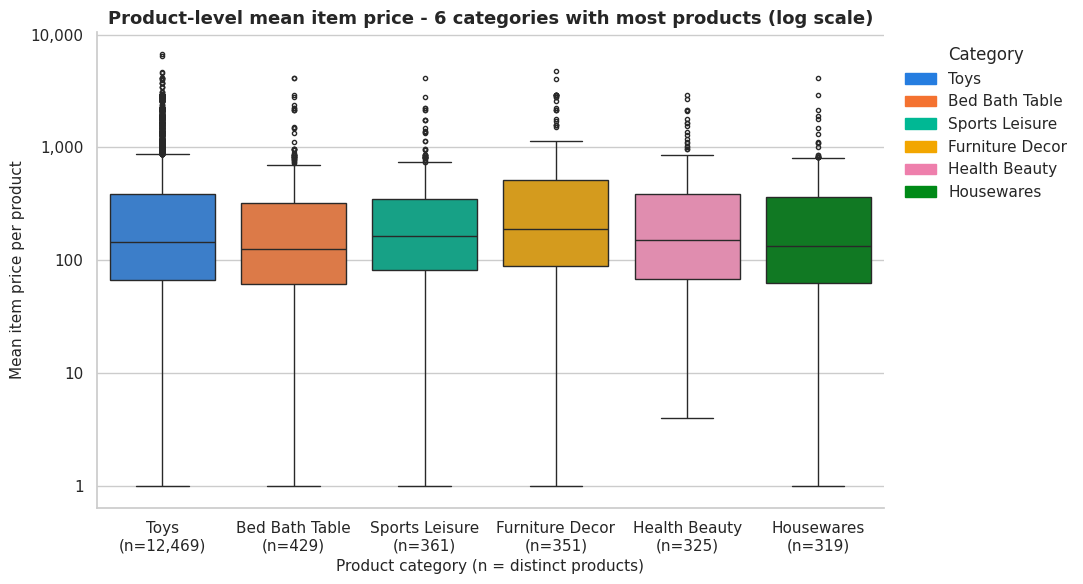

In [89]:
#Q9
prod = items.groupby('product_id').agg(mean_price=('price', 'mean'), category=('category', 'first'))  # 1 row = 1 product
n_products = prod['category'].value_counts()
top6 = n_products.head(6).index.tolist()

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=prod[prod['category'].isin(top6)], x='category', y='mean_price', order=top6,
            hue='category', hue_order=top6, palette=PAL[:6], legend=False, fliersize=3, ax=ax)
ax.set_xticks(range(6))
ax.set_xticklabels([f'{n}\n(n={n_products[c]:,})' for n, c in zip(nice(top6), top6)])
ax.set_yscale('log')
ax.yaxis.set_major_formatter(thousands)
ax.set_title('Product-level mean item price - 6 categories with most products (log scale)')
ax.set_xlabel('Product category (n = distinct products)'); ax.set_ylabel('Mean item price per product')
handles = [Patch(color=PAL[i], label=nice([c])[0]) for i, c in enumerate(top6)]
ax.legend(handles=handles, title='Category', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,,,,,,,
Monday,116,59,25,17,6,3,25,52,180,285,414,411,390,422,443,377,417,396,387,383,401,414,422,279
Tuesday,115,66,33,21,9,14,20,96,186,325,392,418,349,402,418,380,445,391,324,321,409,395,395,266
Wednesday,185,72,38,13,14,15,28,81,184,319,405,391,382,405,420,425,408,361,333,311,332,377,316,229
Thursday,154,62,31,15,19,12,33,80,197,287,371,363,385,389,396,366,443,346,286,323,309,296,351,249
Friday,167,85,31,23,14,12,35,76,177,283,363,368,328,390,378,367,352,310,265,276,240,259,278,219
Saturday,126,81,26,10,10,16,27,39,93,160,252,287,281,274,281,285,238,281,269,268,265,253,202,163
Sunday,95,58,26,18,15,10,10,37,67,138,206,237,261,273,254,258,274,299,346,336,373,338,318,228


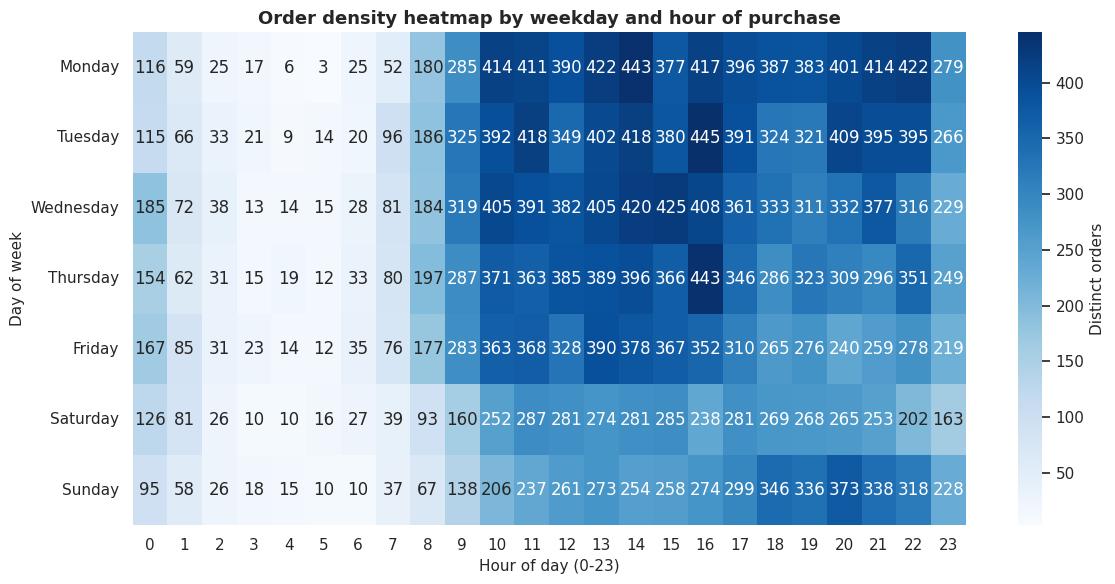

In [90]:
#Q10
heat = (orders.groupby(['weekday', 'hour'])['order_id'].nunique().unstack(fill_value=0)
              .reindex(index=DAYS))
display(heat)

fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(heat, cmap='Blues', annot=True, fmt=',.0f', cbar_kws={'label': 'Distinct orders', 'format': thousands}, ax=ax)
ax.set_title('Order density heatmap by weekday and hour of purchase')
ax.set_xlabel('Hour of day (0-23)'); ax.set_ylabel('Day of week')
plt.tight_layout(); plt.show()

2 products dropped (missing / non-positive weight or volume)


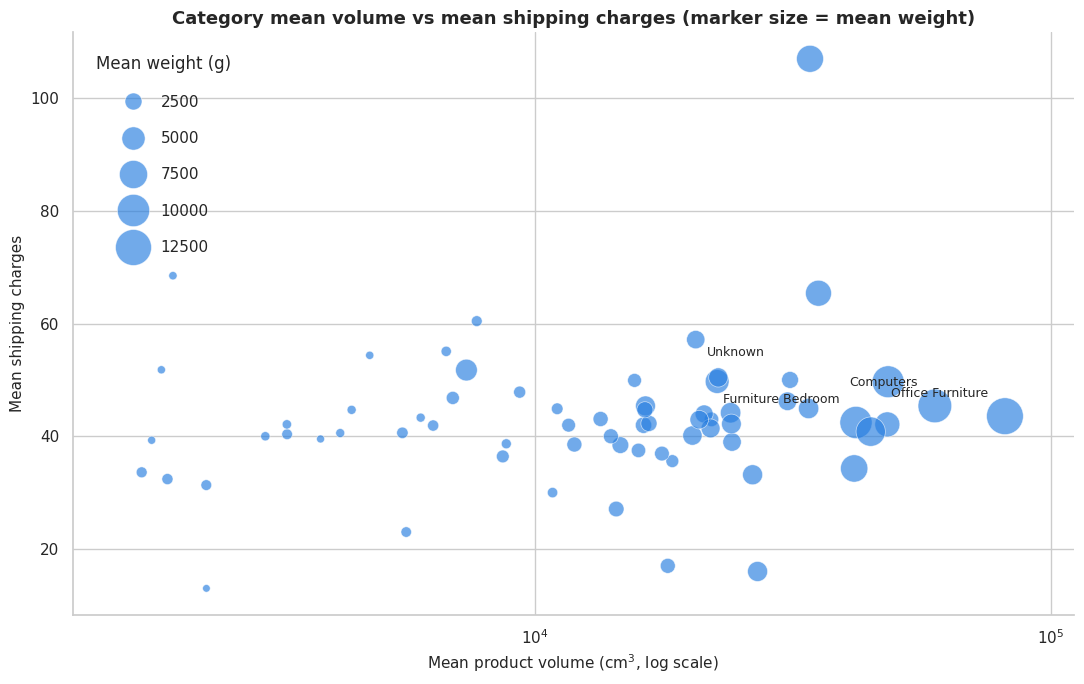

In [91]:
#Q11
valid = products[(products['product_weight_g'] > 0) & (products['volume_cm3'] > 0)]
print(f'{len(products) - len(valid)} products dropped (missing / non-positive weight or volume)')

cat_prod = valid.groupby('category').agg(mean_volume=('volume_cm3', 'mean'),
                                         mean_weight=('product_weight_g', 'mean'),
                                         n_products=('product_id', 'nunique'))
ship = (items[items['product_id'].isin(valid['product_id'])]
        .groupby('category')['shipping_charges'].mean().rename('mean_shipping'))
cat_stats = cat_prod.join(ship, how='inner').reset_index()

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=cat_stats, x='mean_volume', y='mean_shipping', size='mean_weight',
                sizes=(30, 700), alpha=0.65, color=PAL[0], edgecolor='white', ax=ax)
for _, r in cat_stats.nlargest(3, 'mean_weight').iterrows():
    ax.annotate(nice([r.category])[0], (r.mean_volume, r.mean_shipping), xytext=(-12, 14),
                textcoords='offset points', ha='right', fontsize=9)
for _, r in cat_stats[cat_stats['category'] == 'Unknown'].iterrows():
    ax.annotate('Unknown', (r.mean_volume, r.mean_shipping), xytext=(8, -12), textcoords='offset points', fontsize=9)
ax.set_xscale('log'); ax.margins(x=0.08)
ax.set_title('Category mean volume vs mean shipping charges (marker size = mean weight)')
ax.set_xlabel('Mean product volume (cm$^3$, log scale)'); ax.set_ylabel('Mean shipping charges')
ax.legend(title='Mean weight (g)', loc='upper left', labelspacing=1.4, borderpad=1)
plt.tight_layout(); plt.show()

,total_payment,first,last,months
year,,,,
2016,"33,585.00",2016-10-03 16:56:50,2016-12-23 23:16:47,2
2017,"4,759,972.00",2017-01-05 12:01:20,2017-12-31 21:10:02,12
2018,"5,453,883.00",2018-01-01 02:48:41,2018-09-03 09:06:57,9


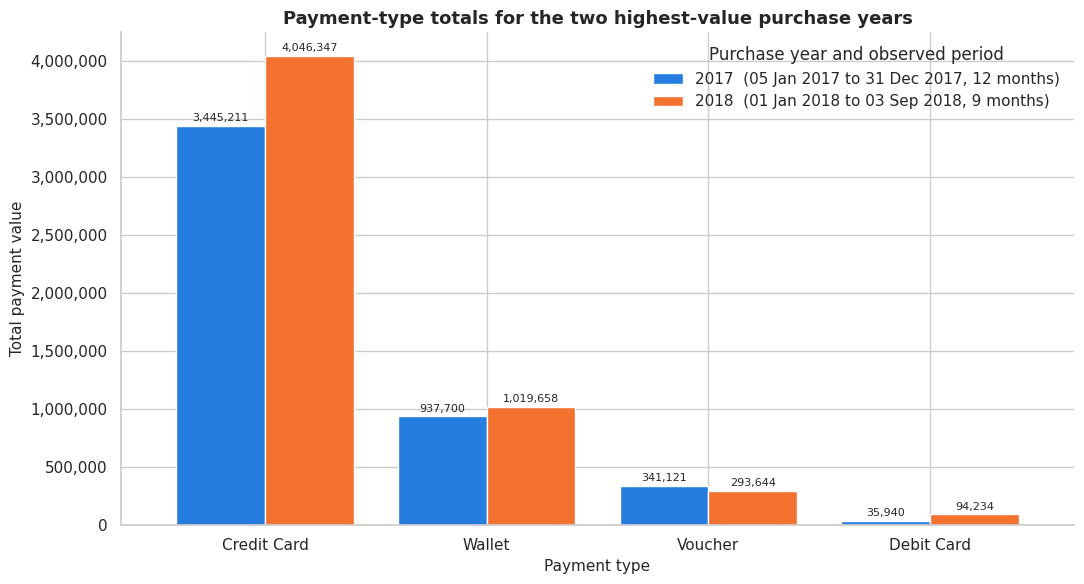

In [92]:
#Q12
year_totals = pay.groupby('year')['payment_value'].sum()
top_years = sorted(year_totals.nlargest(2).index)
cover = pay.groupby('year')['purchase_ts'].agg(first='min', last='max', months=lambda s: s.dt.to_period('M').nunique())
display(pd.concat([year_totals.rename('total_payment'), cover], axis=1))

tbl = (pay[pay['year'].isin(top_years)].groupby(['payment_type', 'year'])['payment_value'].sum()
         .unstack().reindex(PAY_ORDER))
tbl.columns = [f'{y}  ({cover.loc[y, "first"]:%d %b %Y} to {cover.loc[y, "last"]:%d %b %Y}, '
               f'{cover.loc[y, "months"]} months)' for y in tbl.columns]
tbl.index = nice(tbl.index)
ax = tbl.plot(kind='bar', figsize=(11, 6), color=[PAL[0], PAL[1]], width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt='{:,.0f}', fontsize=8, padding=2)
ax.set_title('Payment-type totals for the two highest-value purchase years')
ax.set_xlabel('Payment type'); ax.set_ylabel('Total payment value')
ax.yaxis.set_major_formatter(thousands)
plt.setp(ax.get_xticklabels(), rotation=0)
ax.legend(title='Purchase year and observed period')
plt.tight_layout(); plt.show()

payment_type,credit_card %,wallet %,voucher %,debit_card %
customer_state,,,,
SP,74.14,18.41,6.27,1.18
RJ,74.46,16.54,7.10,1.89
MG,73.98,18.83,5.75,1.44
RS,66.56,28.19,4.78,0.46


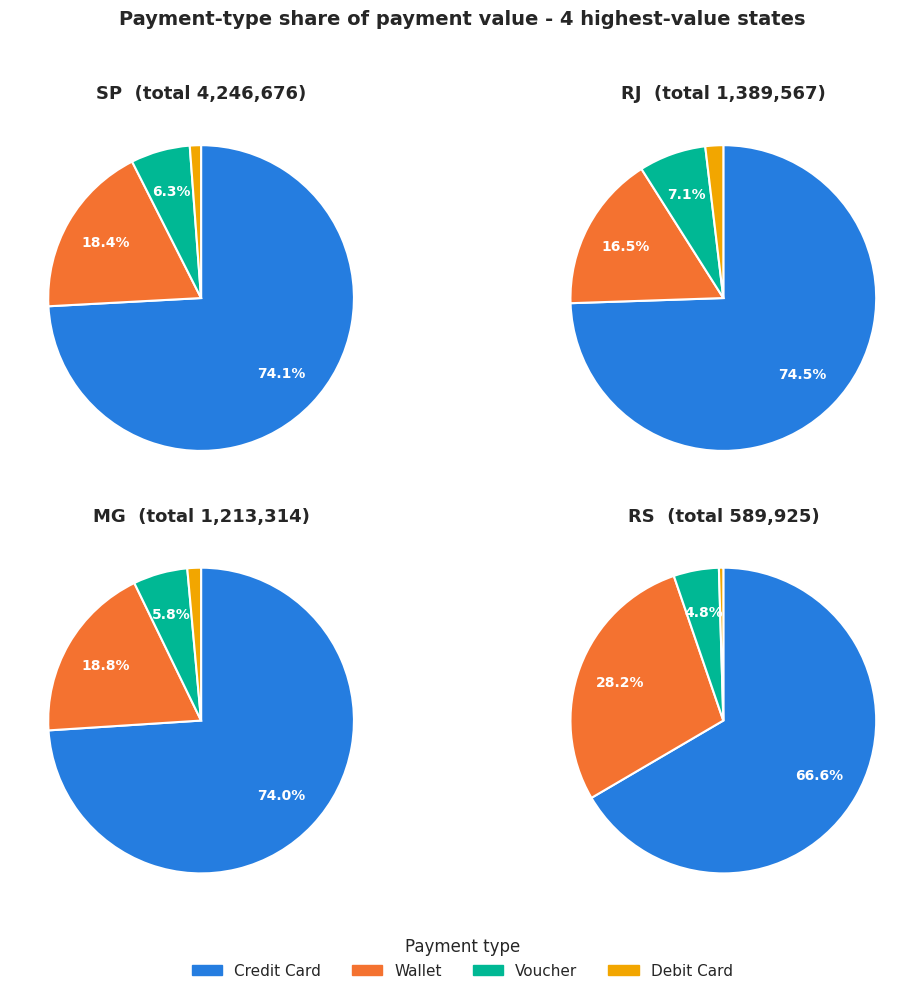

In [93]:
#Q13
top4 = pay.groupby('customer_state')['payment_value'].sum().nlargest(4).index.tolist()
shares = (pay[pay['customer_state'].isin(top4)].groupby(['customer_state', 'payment_type'])['payment_value'].sum()
          .unstack(fill_value=0).reindex(index=top4, columns=PAY_ORDER, fill_value=0))
pct = shares.div(shares.sum(axis=1), axis=0) * 100
display(pct.round(2).add_suffix(' %'))

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for ax, st in zip(axes.ravel(), top4):
    ax.pie(shares.loc[st], colors=[PAY_COLORS[t] for t in PAY_ORDER], startangle=90, counterclock=False,
           autopct=lambda p: f'{p:.1f}%' if p >= 3 else '', pctdistance=0.72,
           textprops={'color': 'white', 'fontsize': 10, 'fontweight': 'bold'},
           wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
    ax.set_title(f'{st}  (total {shares.loc[st].sum():,.0f})')
fig.legend(handles=[Patch(color=PAY_COLORS[t], label=nice([t])[0]) for t in PAY_ORDER],
           loc='lower center', ncol=4, title='Payment type')
fig.suptitle('Payment-type share of payment value - 4 highest-value states', fontsize=14, fontweight='bold')
plt.tight_layout(rect=(0, 0.06, 1, 0.96)); plt.show()



Excluded: 7 without approval time, 0 negative -> 38,272 valid orders


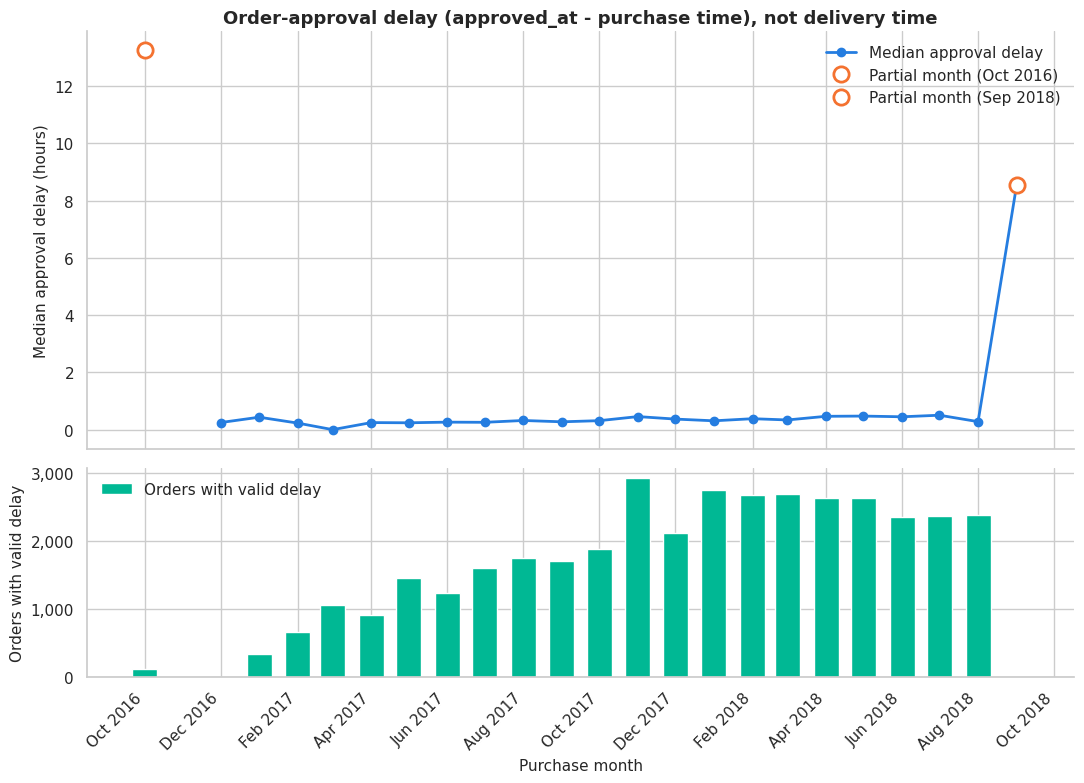

,median_delay_h,valid_orders
2016-10,13.25,113.00
2016-11,NaN,NaN
2016-12,0.25,1.00
2017-01,0.43,332.00
2017-02,0.23,657.00
2017-03,0.00,"1,058.00"
2017-04,0.25,908.00
2017-05,0.24,"1,461.00"
2017-06,0.26,"1,238.00"
2017-07,0.26,"1,602.00"


In [94]:
#Q14
d = orders.copy()
n_missing = d['approved_ts'].isna().sum()
d['approval_delay_h'] = (d['approved_ts'] - d['purchase_ts']).dt.total_seconds() / 3600   # approval - purchase
n_neg = (d['approval_delay_h'] < 0).sum()
d = d[d['approval_delay_h'] >= 0]                                  # drops missing and negative delays
print(f'Excluded: {n_missing} without approval time, {n_neg} negative -> {len(d):,} valid orders')

mm = d.groupby('month')['approval_delay_h'].agg(median_delay_h='median', valid_orders='count')
mm = full_months(mm)
x = mm.index.to_timestamp()

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(11, 8), height_ratios=[2, 1])
ax1.plot(x, mm['median_delay_h'], marker='o', color=PAL[0], lw=2, label='Median approval delay')
for p, note in PARTIAL.items():
    ax1.plot(p.to_timestamp(), mm.loc[p, 'median_delay_h'], 'o', ms=11, mfc='white', mec=PAL[1], mew=2,
             label=f'Partial month ({p.strftime("%b %Y")})')
ax1.set_ylabel('Median approval delay (hours)')
ax1.set_title('Order-approval delay (approved_at - purchase time), not delivery time')
ax1.legend(loc='upper right')
ax2.bar(x, mm['valid_orders'], width=20, color=PAL[2], label='Orders with valid delay')
ax2.set_ylabel('Orders with valid delay'); ax2.set_xlabel('Purchase month')
ax2.yaxis.set_major_formatter(thousands); ax2.legend(loc='upper left')
month_axis(ax2)
plt.tight_layout(); plt.show()
display(mm.rename(index=str))

,label,total_item_price,distinct_orders
2519,Sao Paulo (SP),"2,002,615.00",6160
2197,Rio De Janeiro (RJ),"918,209.00",2730
312,Belo Horizonte (MG),"379,168.00",1086
394,Brasilia (DF),"286,364.00",837
2071,Porto Alegre (RS),"231,138.00",577
799,Curitiba (PR),"201,513.00",562
1061,Guarulhos (SP),"197,316.00",483
496,Campinas (SP),"194,074.00",555
2264,Salvador (BA),"164,152.00",489
2399,Sao Bernardo Do Campo (SP),"129,758.00",359


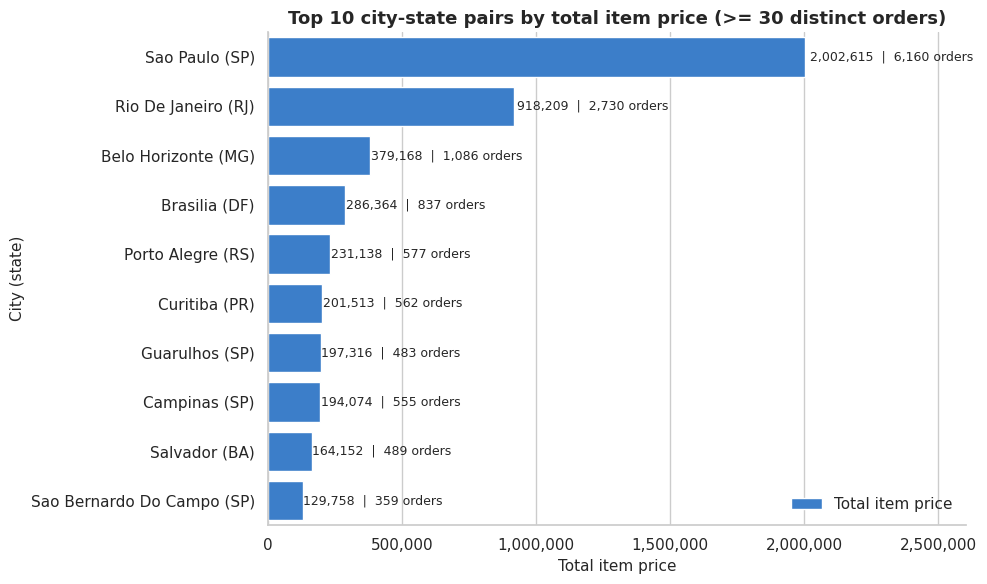

In [95]:
#Q15
cs = (items.groupby(['customer_city', 'customer_state'])
           .agg(total_item_price=('price', 'sum'), distinct_orders=('order_id', 'nunique')).reset_index())
cs = cs[cs['distinct_orders'] >= 30]
top = cs.nlargest(10, 'total_item_price').copy()
top['label'] = top['customer_city'].str.title() + ' (' + top['customer_state'] + ')'   # city + state keeps pairs distinct
display(top[['label', 'total_item_price', 'distinct_orders']])

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top, x='total_item_price', y='label', orient='h', color=PAL[0], errorbar=None,
            label='Total item price', ax=ax)
for b, n in zip(ax.patches, top['distinct_orders']):
    ax.text(b.get_width() * 1.01, b.get_y() + b.get_height() / 2, f'{b.get_width():,.0f}  |  {n:,} orders',
            va='center', fontsize=9)
ax.set_xlim(0, top['total_item_price'].max() * 1.3)
ax.xaxis.set_major_formatter(thousands)
ax.set_title('Top 10 city-state pairs by total item price (>= 30 distinct orders)')
ax.set_xlabel('Total item price'); ax.set_ylabel('City (state)')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

band,1,2-3,4-6,7+
2018-03,"190,861.00","137,785.00","92,830.00","91,669.00"
2018-04,"180,831.00","151,262.00","100,151.00","87,731.00"
2018-05,"195,129.00","148,720.00","111,415.00","84,849.00"
2018-06,"146,826.00","149,562.00","98,585.00","85,407.00"
2018-07,"144,761.00","119,065.00","98,164.00","72,960.00"
2018-08,"148,311.00","131,240.00","89,133.00","66,062.00"


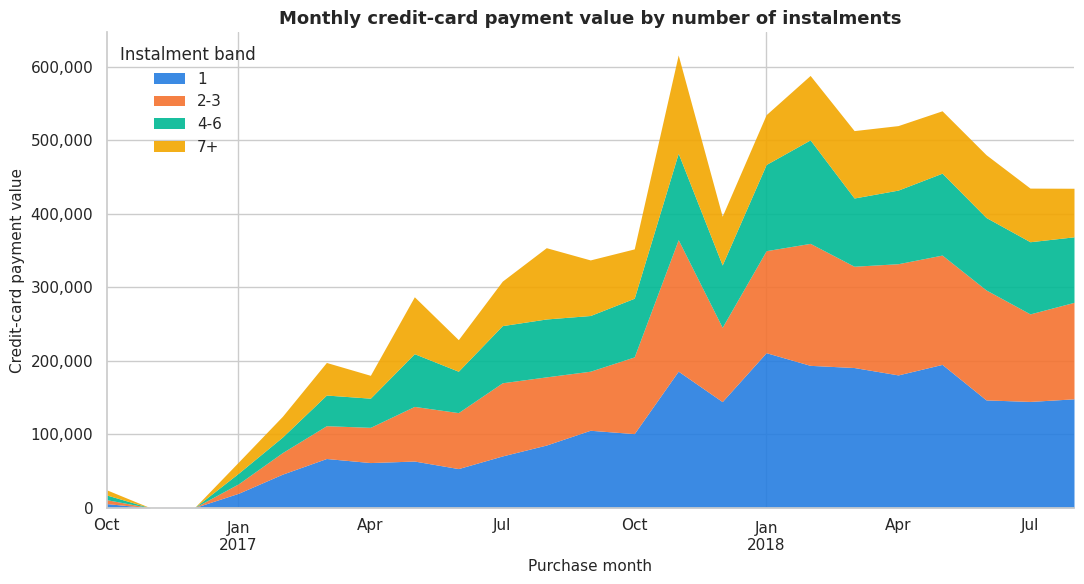

In [96]:
#Q16
cc = pay[(pay['payment_type'] == 'credit_card') & pay['payment_installments'].notna()
         & (pay['payment_installments'] > 0)].copy()
BANDS = ['1', '2-3', '4-6', '7+']
cc['band'] = pd.cut(cc['payment_installments'], bins=[0, 1, 3, 6, np.inf], labels=BANDS)
band_month = (cc.groupby(['month', 'band'], observed=False)['payment_value'].sum().unstack(fill_value=0)[BANDS])
band_month = band_month.reindex(pd.period_range(band_month.index.min(), band_month.index.max(), freq='M'),
                                fill_value=0)
display(band_month.round(0).tail(6))

ax = band_month.plot.area(stacked=True, figsize=(11, 6), color=PAL[:4], alpha=0.9, lw=0)
ax.set_title('Monthly credit-card payment value by number of instalments')
ax.set_xlabel('Purchase month'); ax.set_ylabel('Credit-card payment value')
ax.yaxis.set_major_formatter(thousands)
ax.legend(title='Instalment band', loc='upper left')
plt.tight_layout(); plt.show()

,total_price,total_shipping,lines,shipping_pct
category,,,,
arts_and_craftmanship,37.00,107.00,1,289.19
music,23.00,40.00,1,173.91
agro_industry_and_commerce,"2,198.00",800.00,19,36.40
industry_commerce_and_business,"3,865.00","1,177.00",18,30.45
electronics,"40,006.00","10,063.00",215,25.15
small_appliances_home_oven_and_coffee,"1,222.00",300.00,6,24.55
home_appliances_2,"6,472.00","1,540.00",31,23.79
furniture_mattress_and_upholstery,77.00,17.00,1,22.08
art,945.00,207.00,4,21.90


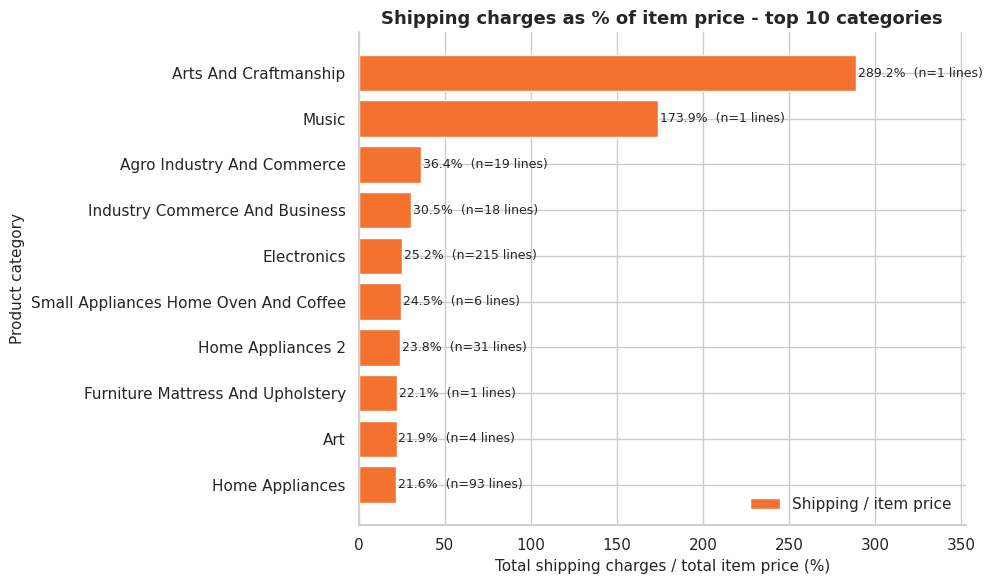

In [97]:
#Q17
cat = (items.groupby('category')
            .agg(total_price=('price', 'sum'), total_shipping=('shipping_charges', 'sum'), lines=('order_id', 'size')))
cat = cat[cat['total_price'] > 0].copy()
cat['shipping_pct'] = cat['total_shipping'] / cat['total_price'] * 100     # from category totals
top10 = cat.nlargest(10, 'shipping_pct')
display(top10)

fig, ax = plt.subplots(figsize=(10, 6))
rev = top10.iloc[::-1]
bars = ax.barh(nice(rev.index), rev['shipping_pct'], color=PAL[1], label='Shipping / item price')
for b, n in zip(bars, rev['lines']):
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, f'{b.get_width():.1f}%  (n={n:,} lines)',
            va='center', fontsize=9)
ax.set_xlim(0, top10['shipping_pct'].max() * 1.22)
ax.set_title('Shipping charges as % of item price - top 10 categories')
ax.set_xlabel('Total shipping charges / total item price (%)'); ax.set_ylabel('Product category')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

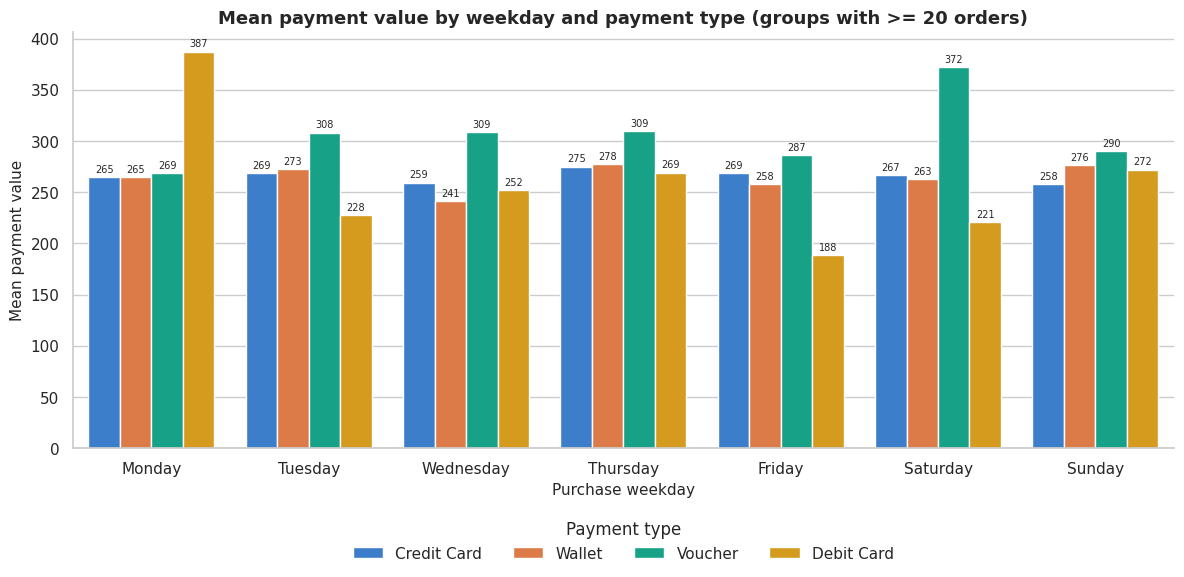

In [98]:
#Q18
grp = (pay.groupby(['weekday', 'payment_type'])
          .agg(mean_payment=('payment_value', 'mean'), distinct_orders=('order_id', 'nunique')).reset_index())
grp = grp[grp['distinct_orders'] >= 20]

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=grp, x='weekday', y='mean_payment', hue='payment_type', order=DAYS, hue_order=PAY_ORDER,
            palette=PAY_COLORS, errorbar=None, ax=ax)
for c in ax.containers:
    ax.bar_label(c, labels=[f'{b.get_height():,.0f}' if np.isfinite(b.get_height()) and b.get_height() > 0 else ''
                            for b in c], fontsize=7, padding=2)
ax.set_title('Mean payment value by weekday and payment type (groups with >= 20 orders)')
ax.set_xlabel('Purchase weekday'); ax.set_ylabel('Mean payment value')
ax.legend(title='Payment type', labels=nice(PAY_ORDER), ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.14))
plt.tight_layout(); plt.show()

Combined 38,279 rows from 3 extracts - no lost or duplicated order IDs.


,total_item_price,distinct_orders,first_order,last_order,months_observed,incomplete
year,,,,,,
2016,"36,712.00",114,2016-10-03 16:56:50,2016-12-23 23:16:47,2,True
2017,"6,209,478.00",17658,2017-01-05 12:01:20,2017-12-31 21:10:02,12,False
2018,"6,865,642.00",20507,2018-01-01 02:48:41,2018-09-03 09:06:57,9,True


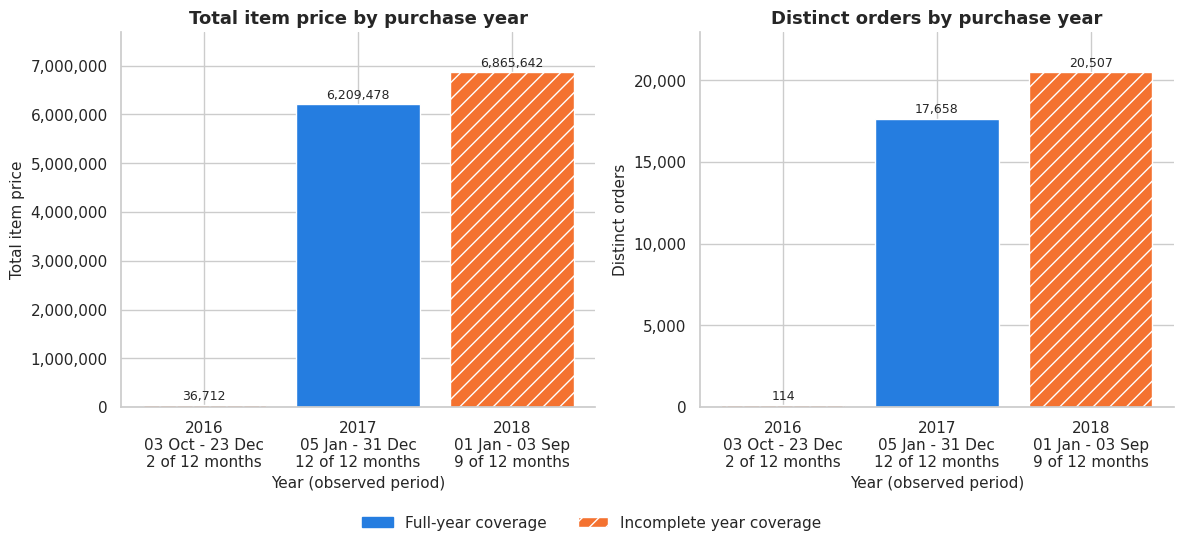

In [99]:
#Q19
YEARS = [2016, 2017, 2018]
extracts = {y: items.loc[items['year'] == y, ['order_id', 'price', 'purchase_ts']] for y in YEARS}
combined = pd.concat(extracts.values(), ignore_index=True)

assert combined['order_id'].is_unique, 'duplicated order IDs after combining'
assert set(combined['order_id']) == set(items['order_id']) and len(combined) == len(items), 'order IDs lost'
assert np.isclose(combined['price'].sum(), items['price'].sum())
print(f'Combined {len(combined):,} rows from {len(extracts)} extracts - no lost or duplicated order IDs.')

combined['year'] = combined['purchase_ts'].dt.year
annual = combined.groupby('year').agg(total_item_price=('price', 'sum'), distinct_orders=('order_id', 'nunique'),
                                      first_order=('purchase_ts', 'min'), last_order=('purchase_ts', 'max'),
                                      months_observed=('purchase_ts', lambda s: s.dt.to_period('M').nunique()))
annual['incomplete'] = (annual['months_observed'] < 12) | annual.index.map(
    lambda y: any(p.year == y for p in PARTIAL))
display(annual)

xl = [f'{y}\n{r.first_order:%d %b} - {r.last_order:%d %b}\n{r.months_observed} of 12 months' for y, r in annual.iterrows()]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, col, title in zip(axes, ['total_item_price', 'distinct_orders'], ['Total item price', 'Distinct orders']):
    bars = ax.bar(xl, annual[col], color=[PAL[1] if inc else PAL[0] for inc in annual['incomplete']])
    for b, inc in zip(bars, annual['incomplete']):
        if inc: b.set_hatch('//'); b.set_edgecolor('white')
    ax.bar_label(bars, labels=[f'{v:,.0f}' for v in annual[col]], padding=2, fontsize=9)
    ax.set_title(f'{title} by purchase year'); ax.set_ylabel(title); ax.yaxis.set_major_formatter(thousands)
    ax.set_ylim(0, annual[col].max() * 1.12); ax.set_xlabel('Year (observed period)')
fig.legend(handles=[Patch(color=PAL[0], label='Full-year coverage'),
                    Patch(facecolor=PAL[1], hatch='//', edgecolor='white', label='Incomplete year coverage')],
           loc='lower center', ncol=2)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

Rebuilt 38,279 payments from 4 extracts - identical to the source table.


,total_payment,mean_installments
payment_type,,
credit_card,"7,516,504.00",3.68
wallet,"1,963,594.00",1.00
voucher,"637,168.00",1.00
debit_card,"130,174.00",1.00


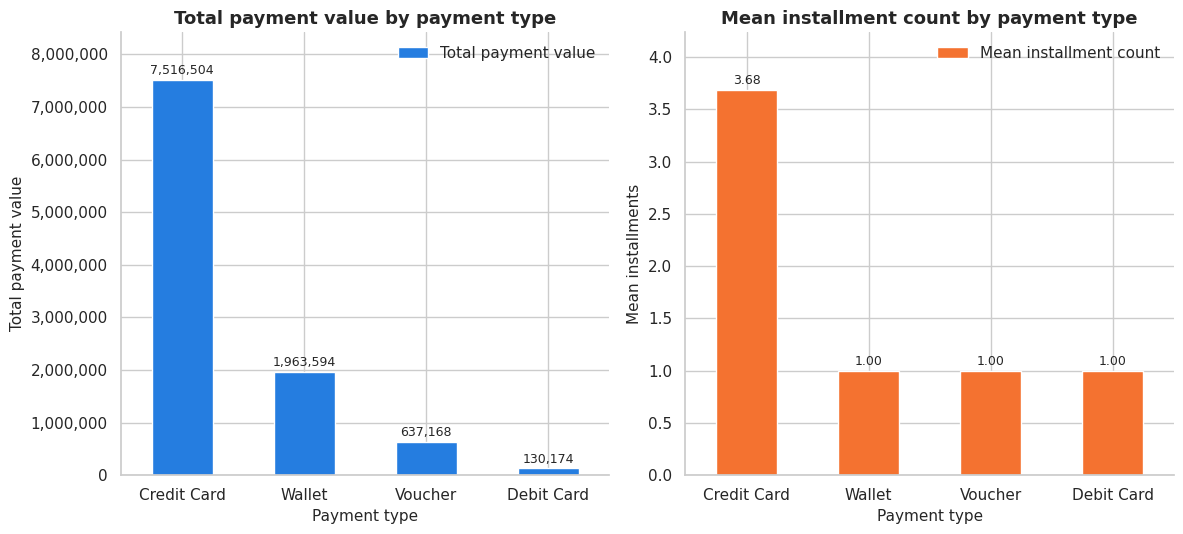

In [100]:
#Q20
assert payments['payment_type'].notna().all()
type_extracts = {t: payments[payments['payment_type'] == t] for t in payments['payment_type'].unique()}
rebuilt = pd.concat(type_extracts.values(), ignore_index=True)

key = ['order_id', 'payment_sequential']
assert len(rebuilt) == len(payments) and not rebuilt.duplicated(key).any()
pd.testing.assert_frame_equal(rebuilt.sort_values(key).reset_index(drop=True),
                              payments.sort_values(key).reset_index(drop=True))
print(f'Rebuilt {len(rebuilt):,} payments from {len(type_extracts)} extracts - identical to the source table.')

summary = (rebuilt.groupby('payment_type')
                  .agg(total_payment=('payment_value', 'sum'), mean_installments=('payment_installments', 'mean')))
summary = summary.sort_values('total_payment', ascending=False)       # same category order in both panels
display(summary)

summary.index = nice(summary.index)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
summary['total_payment'].plot(kind='bar', ax=axes[0], color=PAL[0], label='Total payment value')
axes[0].bar_label(axes[0].containers[0], labels=[f'{v:,.0f}' for v in summary['total_payment']], fontsize=9, padding=2)
axes[0].set_title('Total payment value by payment type'); axes[0].set_ylabel('Total payment value')
axes[0].yaxis.set_major_formatter(thousands); axes[0].set_ylim(0, summary['total_payment'].max() * 1.12)
summary['mean_installments'].plot(kind='bar', ax=axes[1], color=PAL[1], label='Mean installment count')
axes[1].bar_label(axes[1].containers[0], labels=[f'{v:.2f}' for v in summary['mean_installments']], fontsize=9, padding=2)
axes[1].set_title('Mean installment count by payment type'); axes[1].set_ylabel('Mean installments')
axes[1].set_ylim(0, summary['mean_installments'].max() * 1.15)
for ax in axes:
    ax.set_xlabel('Payment type'); plt.setp(ax.get_xticklabels(), rotation=0); ax.legend()
plt.tight_layout(); plt.show()

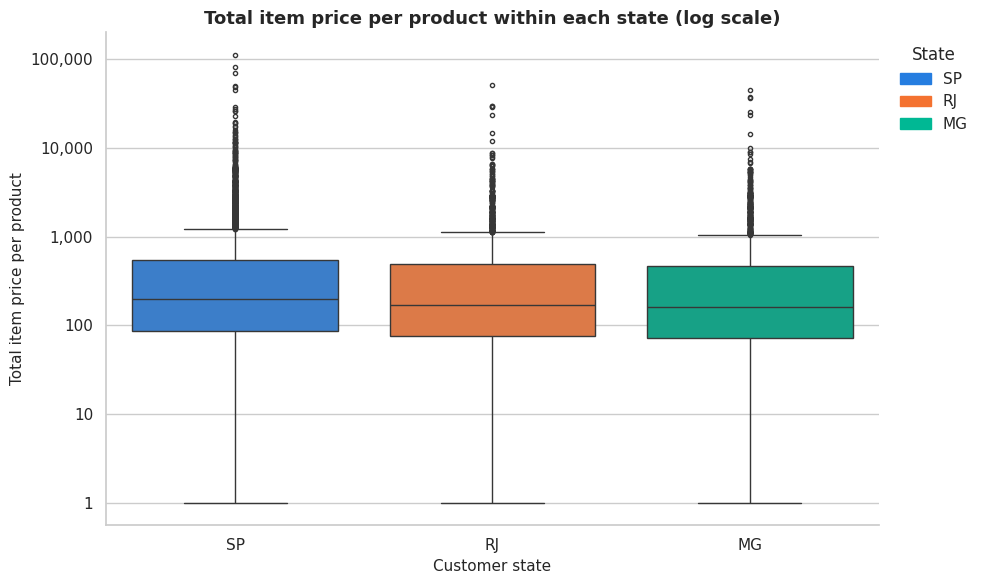

,count,min,25%,50%,75%,max
customer_state,,,,,,
SP,"8,939.00",1.00,86.00,198.00,543.50,"112,089.00"
RJ,"3,442.00",1.00,76.00,171.00,496.00,"50,966.00"
MG,"3,030.00",1.00,72.00,161.00,462.75,"44,449.00"


In [101]:
#Q21
REGIONS = ['SP', 'RJ', 'MG']
region_extracts = {s: customers[customers['customer_state'] == s] for s in REGIONS}
reg_customers = pd.concat(region_extracts.values(), ignore_index=True)
assert reg_customers['customer_id'].is_unique and len(reg_customers) == customers['customer_state'].isin(REGIONS).sum()

reg_items = (items.drop(columns=['customer_state', 'customer_city'])
                  .merge(reg_customers[['customer_id', 'customer_state']], on='customer_id',
                         how='inner', validate='many_to_one'))
state_prod = (reg_items.groupby(['customer_state', 'product_id'])['price'].sum()
                       .rename('total_item_price').reset_index())      # one observation = one state-product total

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=state_prod, x='customer_state', y='total_item_price', order=REGIONS, hue='customer_state',
            hue_order=REGIONS, palette=PAL[:3], legend=False, fliersize=3, ax=ax)
ax.set_yscale('log'); ax.yaxis.set_major_formatter(thousands)
ax.set_title('Total item price per product within each state (log scale)')
ax.set_xlabel('Customer state'); ax.set_ylabel('Total item price per product')
ax.legend(handles=[Patch(color=PAL[i], label=s) for i, s in enumerate(REGIONS)], title='State',
          bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()
display(state_prod.groupby('customer_state')['total_item_price']
        .describe()[['count', 'min', '25%', '50%', '75%', 'max']].reindex(REGIONS))



,total_item_price,distinct_orders,mean_shipping
group,,,
Toys,"9,795,863.00",28697,44.70
Other,"3,315,969.00",9582,42.80


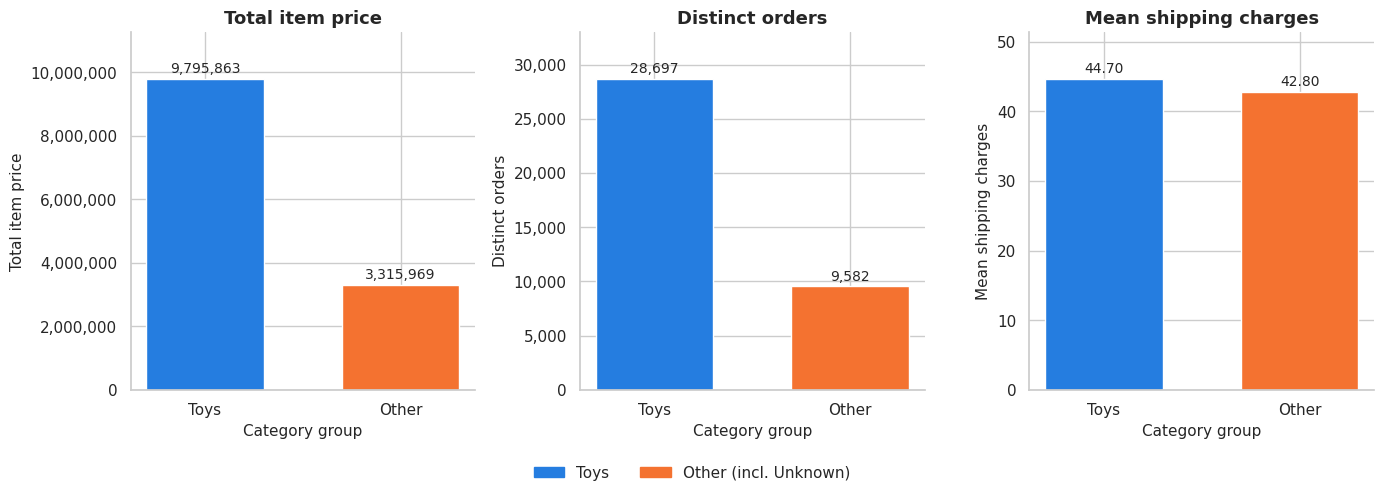

In [102]:
#Q22
cols = ['order_id', 'category', 'price', 'shipping_charges']
toys_extract  = items.loc[items['category'] == 'toys', cols]
other_extract = items.loc[items['category'] != 'toys', cols]
labelled = pd.concat([toys_extract.assign(group='Toys'), other_extract.assign(group='Other')], ignore_index=True)
assert len(labelled) == len(items) and labelled['order_id'].nunique() == items['order_id'].nunique()

cmp = (labelled.groupby('group')
       .agg(total_item_price=('price', 'sum'), distinct_orders=('order_id', 'nunique'),
            mean_shipping=('shipping_charges', 'mean')).reindex(['Toys', 'Other']))
display(cmp)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
specs = [('total_item_price', 'Total item price', '{:,.0f}'), ('distinct_orders', 'Distinct orders', '{:,.0f}'),
         ('mean_shipping', 'Mean shipping charges', '{:,.2f}')]
for ax, (col, title, fmt) in zip(axes, specs):
    bars = ax.bar(cmp.index, cmp[col], color=[PAL[0], PAL[1]], width=0.6)
    ax.bar_label(bars, labels=[fmt.format(v) for v in cmp[col]], padding=2, fontsize=10)
    ax.set_title(title); ax.set_ylabel(title); ax.set_xlabel('Category group')
    ax.set_ylim(0, cmp[col].max() * 1.15)
    if col != 'mean_shipping': ax.yaxis.set_major_formatter(thousands)
fig.legend(handles=[Patch(color=PAL[0], label='Toys'), Patch(color=PAL[1], label='Other (incl. Unknown)')],
           loc='lower center', ncol=2)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

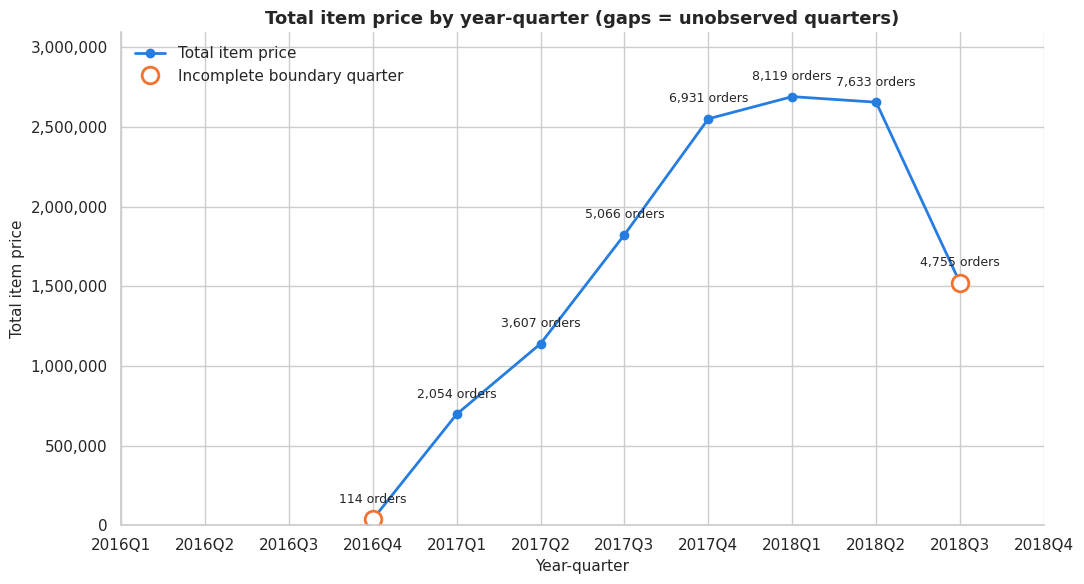

In [103]:
#Q23
q_extracts = {q: items[items['purchase_ts'].dt.quarter == q] for q in (1, 2, 3, 4)}
allq = pd.concat(q_extracts.values(), ignore_index=True)
assert len(allq) == len(items) and allq['order_id'].is_unique

quarterly = allq.groupby('yq').agg(total_item_price=('price', 'sum'), distinct_orders=('order_id', 'nunique'),
                                   months_observed=('month', 'nunique'))
quarterly['incomplete'] = (quarterly['months_observed'] < 3) | quarterly.index.isin([p.asfreq('Q') for p in PARTIAL])
all_q = pd.period_range(f'{allq["yq"].min().year}Q1', f'{allq["yq"].max().year}Q4', freq='Q')
quarterly = quarterly.reindex(all_q)

qplot = quarterly.copy(); qplot.index = qplot.index.astype(str)
ax = qplot['total_item_price'].plot(kind='line', marker='o', lw=2, color=PAL[0], figsize=(11, 6),
                                    label='Total item price')
for i, (p, r) in enumerate(quarterly.iterrows()):
    if r['incomplete'] == True:
        ax.plot(i, r['total_item_price'], 'o', ms=12, mfc='white', mec=PAL[1], mew=2)
ax.plot([], [], 'o', ms=12, mfc='white', mec=PAL[1], mew=2, label='Incomplete boundary quarter')
for i, (p, r) in enumerate(quarterly.iterrows()):
    if pd.notna(r['distinct_orders']):
        ax.annotate(f'{int(r["distinct_orders"]):,} orders', (i, r['total_item_price']), xytext=(0, 12),
                    textcoords='offset points', ha='center', fontsize=9)
ax.set_xticks(range(len(qplot))); ax.set_xticklabels(qplot.index, rotation=0)
ax.set_title('Total item price by year-quarter (gaps = unobserved quarters)')
ax.set_xlabel('Year-quarter'); ax.set_ylabel('Total item price')
ax.yaxis.set_major_formatter(thousands); ax.set_ylim(0, quarterly['total_item_price'].max() * 1.15)
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

month,Oct 2016,Dec 2016,Jan 2017,Feb 2017,Mar 2017,Apr 2017,May 2017,Jun 2017,Jul 2017,Aug 2017,Sep 2017,Oct 2017,Nov 2017,Dec 2017,Jan 2018,Feb 2018,Mar 2018,Apr 2018,May 2018,Jun 2018,Jul 2018,Aug 2018,Sep 2018
group,,,,,,,,,,,,,,,,,,,,,,,
Wallet,18.60,0.00,25.80,21.10,21.60,18.90,18.30,22.20,19.00,19.20,22.00,21.50,20.50,20.60,20.30,18.80,17.30,19.20,18.70,16.80,19.10,16.90,0.00
Non-wallet,81.40,100.00,74.20,78.90,78.40,81.10,81.70,77.80,81.00,80.80,78.00,78.50,79.50,79.40,79.70,81.20,82.70,80.80,81.30,83.20,80.90,83.10,100.00


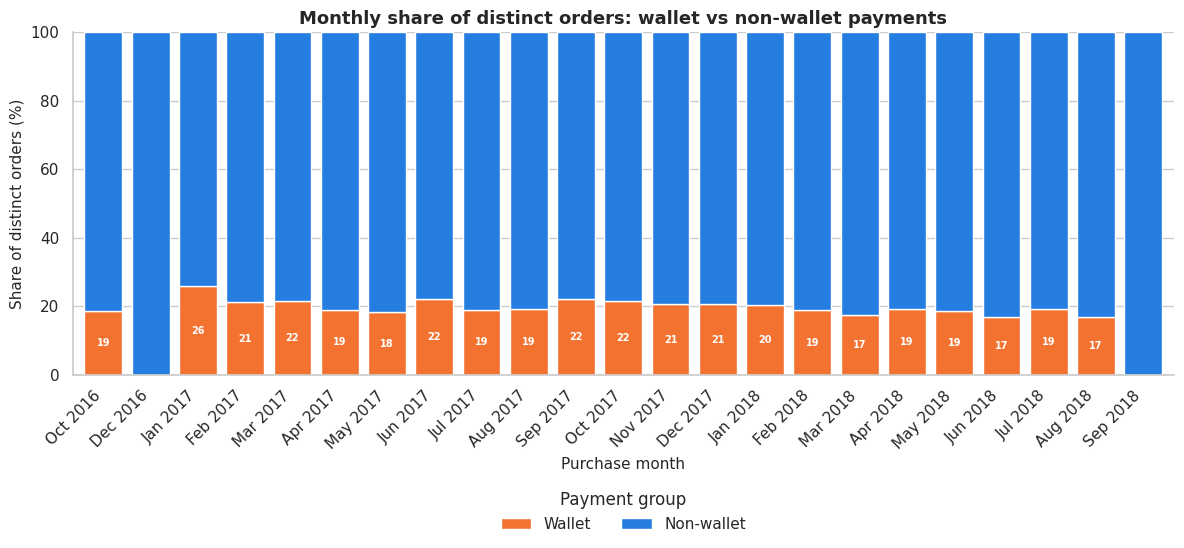

In [104]:
#Q24
is_wallet = pay['payment_type'] == 'wallet'
ext = pd.concat([pay[is_wallet].assign(group='Wallet'), pay[~is_wallet].assign(group='Non-wallet')], ignore_index=True)
assert len(ext) == len(pay)

cnt = (ext.groupby(['month', 'group'])['order_id'].nunique().unstack(fill_value=0)[['Wallet', 'Non-wallet']])
cnt = cnt[cnt.sum(axis=1) > 0]
share = cnt.div(cnt.sum(axis=1), axis=0) * 100
share.index = share.index.strftime('%b %Y')
display(share.round(1).T)

ax = share.plot(kind='bar', stacked=True, figsize=(12, 6), color=[PAL[1], PAL[0]], edgecolor='white', width=0.8)
for i, v in enumerate(share['Wallet']):
    if v > 0: ax.text(i, v / 2, f'{v:.0f}', ha='center', va='center', fontsize=7, color='white', fontweight='bold')
ax.set_ylim(0, 100)
ax.set_title('Monthly share of distinct orders: wallet vs non-wallet payments')
ax.set_xlabel('Purchase month'); ax.set_ylabel('Share of distinct orders (%)')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
ax.legend(title='Payment group', loc='upper center', bbox_to_anchor=(0.5, -0.30), ncol=2)
plt.tight_layout(); plt.show()

Recovered all 16,604 labels; Unknown = 90


,distinct_products,total_item_price
category,,
toys,12469,"9,795,863.00"
bed_bath_table,429,"252,201.00"
sports_leisure,361,"226,183.00"
furniture_decor,351,"340,719.00"
health_beauty,325,"245,294.00"
housewares,319,"169,931.00"
auto,220,"101,966.00"
computers_accessories,220,"203,315.00"
watches_gifts,177,"243,865.00"


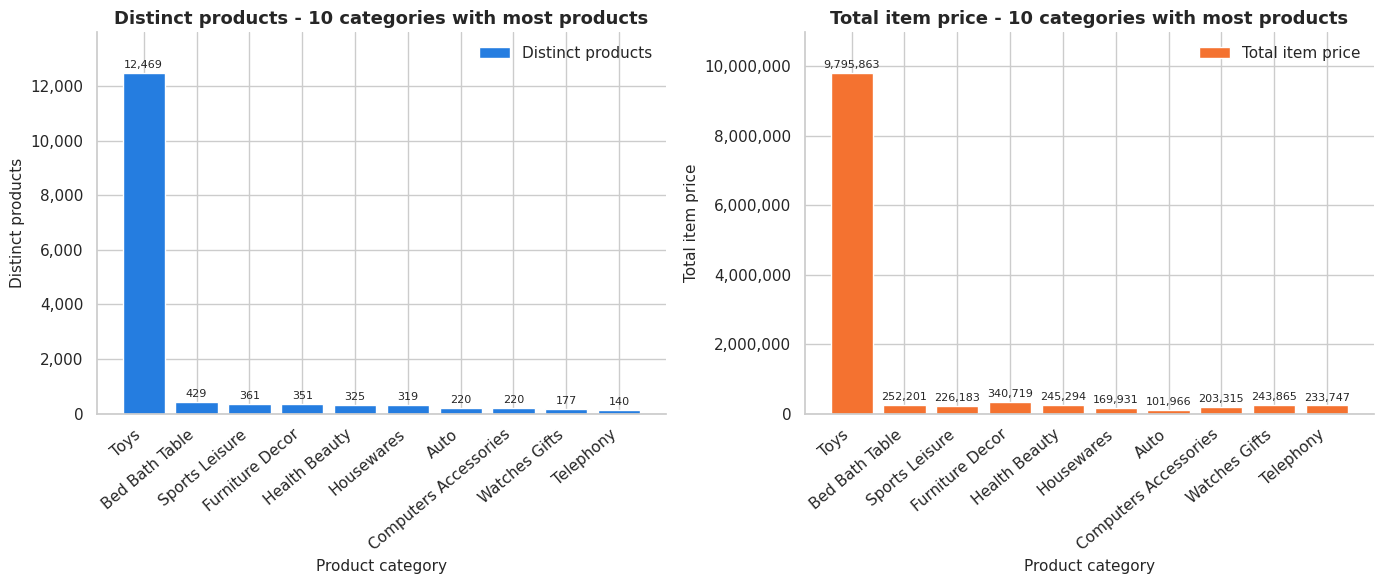

In [105]:
#Q25
prod = products[['product_id', 'product_category_name']].reset_index(drop=True)
pos = np.arange(len(prod))
even_ext = prod['product_category_name'].where(pos % 2 == 0)
odd_ext  = prod['product_category_name'].where(pos % 2 == 1)

recovered = even_ext.combine_first(odd_ext)
recovered = recovered.fillna('Unknown')
assert recovered.equals(prod['product_category_name'].fillna('Unknown')), 'labels differ from the original'
print(f'Recovered all {len(recovered):,} labels; Unknown = {(recovered == "Unknown").sum()}')

rec = prod.assign(category=recovered.values)
rec['total_item_price'] = rec['product_id'].map(order_items.groupby('product_id')['price'].sum()).fillna(0)
res = (rec.groupby('category').agg(distinct_products=('product_id', 'nunique'), total_item_price=('total_item_price', 'sum'))
          .nlargest(10, 'distinct_products'))
display(res)

res.index = nice(res.index)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col, title, colr in zip(axes, ['distinct_products', 'total_item_price'],
                                ['Distinct products', 'Total item price'], [PAL[0], PAL[1]]):
    bars = ax.bar(res.index, res[col], color=colr, label=title)
    ax.bar_label(bars, labels=[f'{v:,.0f}' for v in res[col]], fontsize=8, padding=2)
    ax.set_title(f'{title} - 10 categories with most products'); ax.set_ylabel(title); ax.set_xlabel('Product category')
    ax.yaxis.set_major_formatter(thousands); ax.set_ylim(0, res[col].max() * 1.12)
    plt.setp(ax.get_xticklabels(), rotation=40, ha='right'); ax.legend()
plt.tight_layout(); plt.show()

,2017,2018,combined
customer_state,,,
SP,"2,465,112.00","2,952,566.00","5,417,678.00"
RJ,"825,889.00","834,731.00","1,660,620.00"
MG,"750,283.00","754,622.00","1,504,905.00"
RS,"420,031.00","407,700.00","827,731.00"
PR,"341,637.00","366,409.00","708,046.00"
SC,"235,617.00","226,692.00","462,309.00"
BA,"224,643.00","217,089.00","441,732.00"
DF,"116,458.00","166,877.00","283,335.00"
GO,"125,258.00","151,560.00","276,818.00"


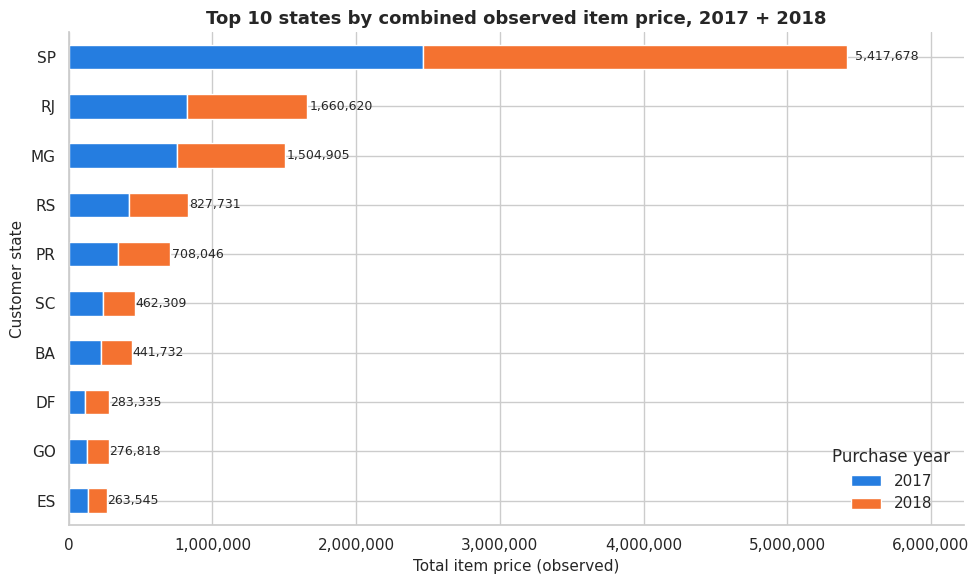

In [106]:
#Q26
e17 = items[items['year'] == 2017].groupby('customer_state')['price'].sum().rename('2017')
e18 = items[items['year'] == 2018].groupby('customer_state')['price'].sum().rename('2018')
recon = pd.concat([e17, e18], axis=1).fillna(0)
recon['combined'] = recon['2017'] + recon['2018']
assert np.isclose(recon['combined'].sum(), items.loc[items['year'].isin([2017, 2018]), 'price'].sum())

top10 = recon.nlargest(10, 'combined')
display(top10)
ax = top10[['2017', '2018']].iloc[::-1].plot(kind='barh', stacked=True, figsize=(10, 6), color=[PAL[0], PAL[1]], edgecolor='white')
for i, v in enumerate(top10['combined'].iloc[::-1]):
    ax.text(v * 1.01, i, f'{v:,.0f}', va='center', fontsize=9)
ax.set_xlim(0, top10['combined'].max() * 1.15); ax.xaxis.set_major_formatter(thousands)
ax.set_title('Top 10 states by combined observed item price, 2017 + 2018')
ax.set_xlabel('Total item price (observed)'); ax.set_ylabel('Customer state')
ax.legend(title='Purchase year')
plt.tight_layout(); plt.show()

,category,mean_weight_g,mean_shipping
0,Toys,"2,213.95",44.70
1,Health Beauty,"1,500.54",41.97
2,Bed Bath Table,"2,218.47",42.28
3,Sports Leisure,"1,883.87",43.06
4,Computers Accessories,876.01,41.90
5,Furniture Decor,"2,848.41",43.96
6,Housewares,"3,049.36",42.94
7,Watches Gifts,484.33,42.11


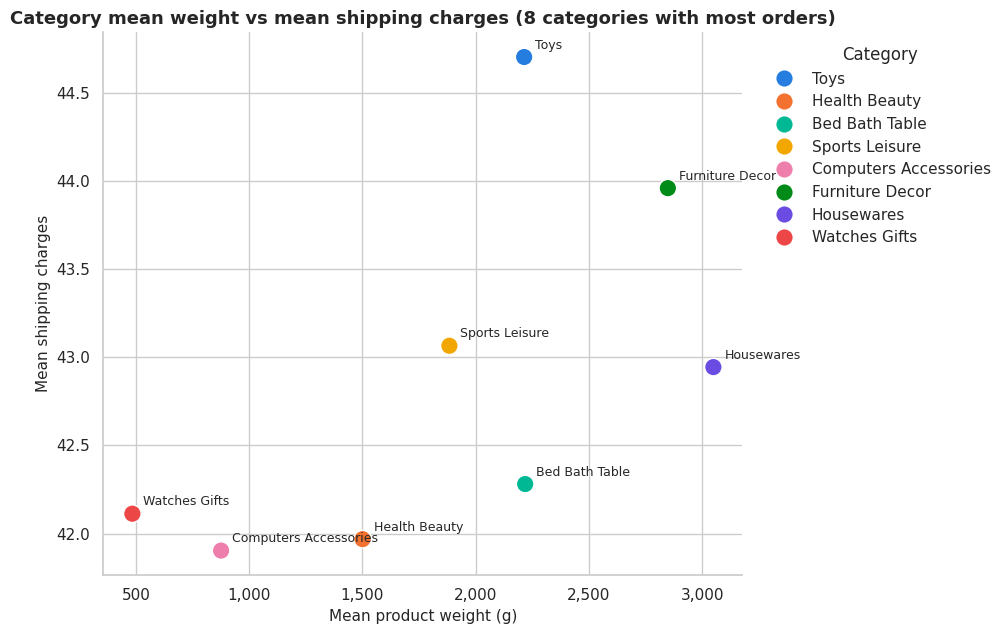

In [107]:
#Q27
w = products.set_index('product_id')['product_weight_g']
pos = np.arange(len(w))
w_even = w.where(pos % 2 == 0)
w_odd  = w.where(pos % 2 == 1)
w_rec = w_even.combine_first(w_odd).reindex(w.index)
pd.testing.assert_series_equal(w_rec, w)

d = items[['order_id', 'product_id', 'category', 'shipping_charges']].copy()
d['weight_g'] = d['product_id'].map(w_rec)
d = d[d['weight_g'] > 0]
top8 = d.groupby('category')['order_id'].nunique().nlargest(8).index.tolist()
d = d[d['category'].isin(top8)]
top8_n = nice(top8)
cs = (d.drop_duplicates('product_id').groupby('category')['weight_g'].mean().rename('mean_weight_g')
        .to_frame().join(d.groupby('category')['shipping_charges'].mean().rename('mean_shipping'))
        .reindex(top8).reset_index())
cs['category'] = nice(cs['category'])
display(cs)

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(data=cs, x='mean_weight_g', y='mean_shipping', hue='category', hue_order=top8_n, palette=PAL[:8],
                s=160, edgecolor='white', ax=ax)
for _, r in cs.iterrows():
    ax.annotate(r.category, (r.mean_weight_g, r.mean_shipping), xytext=(8, 6),
                textcoords='offset points', fontsize=9)
ax.set_title('Category mean weight vs mean shipping charges (8 categories with most orders)')
ax.set_xlabel('Mean product weight (g)'); ax.set_ylabel('Mean shipping charges')
ax.xaxis.set_major_formatter(thousands)
ax.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout(); plt.show()

,2017,2018,diff_2018_minus_2017,partial
month,,,,
Jan,"92,384.00","760,917.00","668,533.00",False
Feb,"167,059.00","749,743.00","582,684.00",False
Mar,"276,610.00","696,831.00","420,221.00",False
Apr,"259,751.00","715,733.00","455,982.00",False
May,"373,067.00","710,366.00","337,299.00",False
Jun,"326,921.00","649,485.00","322,564.00",False
Jul,"430,721.00","579,491.00","148,770.00",False
Aug,"494,764.00","591,251.00","96,487.00",False
Sep,"471,612.00",66.00,"-471,546.00",True


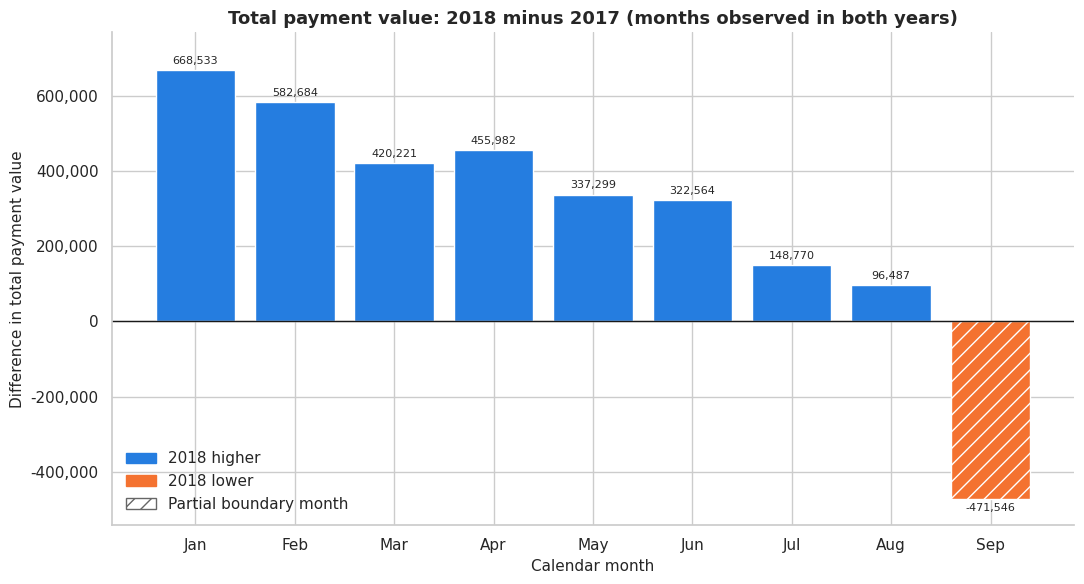

In [108]:
#Q28
p = pay[pay['year'].isin([2017, 2018])].copy()
p['month_num'] = p['purchase_ts'].dt.month
t17 = p[p['year'] == 2017].groupby('month_num')['payment_value'].sum().rename('2017')
t18 = p[p['year'] == 2018].groupby('month_num')['payment_value'].sum().rename('2018')
both = pd.concat([t17, t18], axis=1).reindex(range(1, 13))
both['diff_2018_minus_2017'] = both['2018'] - both['2017']
partial_nums = {per.month for per in PARTIAL if per.year in (2017, 2018)}
both['partial'] = both.index.isin(partial_nums)
both.index = pd.Index(pd.to_datetime(both.index, format='%m').strftime('%b'), name='month')
display(both)

dd = both.dropna(subset=['diff_2018_minus_2017'])
fig, ax = plt.subplots(figsize=(11, 6))
colors = [PAL[0] if v >= 0 else PAL[1] for v in dd['diff_2018_minus_2017']]
bars = ax.bar(dd.index, dd['diff_2018_minus_2017'], color=colors)
for b, part in zip(bars, dd['partial']):
    if part: b.set_hatch('//'); b.set_edgecolor('white')
ax.axhline(0, color=INK, lw=1)
ax.bar_label(bars, labels=[f'{v:,.0f}' for v in dd['diff_2018_minus_2017']], fontsize=8, padding=3)
ax.set_title('Total payment value: 2018 minus 2017 (months observed in both years)')
ax.set_xlabel('Calendar month'); ax.set_ylabel('Difference in total payment value')
ax.yaxis.set_major_formatter(thousands)
lo, hi = dd['diff_2018_minus_2017'].min(), dd['diff_2018_minus_2017'].max()
ax.set_ylim(lo * 1.15 if lo < 0 else 0, hi * 1.15)
ax.legend(handles=[Patch(color=PAL[0], label='2018 higher'), Patch(color=PAL[1], label='2018 lower'),
                   Patch(facecolor='white', edgecolor=MUTED, hatch='//', label='Partial boundary month')],
          loc='lower left')
plt.tight_layout(); plt.show()

year,label,2017,2018,max_mean_price,source
0,Garden Tools,768.76,"1,413.61","1,413.61",2018
1,Costruction Tools Tools,820.00,326.00,820.00,2017
2,Telephony,774.27,425.32,774.27,2017
3,Air Conditioning,768.78,287.43,768.78,2017
4,Fashion Underwear Beach,693.00,601.00,693.00,2017
5,Dvds Blu Ray,617.33,475.00,617.33,2017
6,Construction Tools Construction,594.62,313.85,594.62,2017
7,Tablets Printing Image,104.08,573.00,573.00,2018
8,Office Furniture,561.73,212.05,561.73,2017
9,Watches Gifts,526.75,486.76,526.75,2017


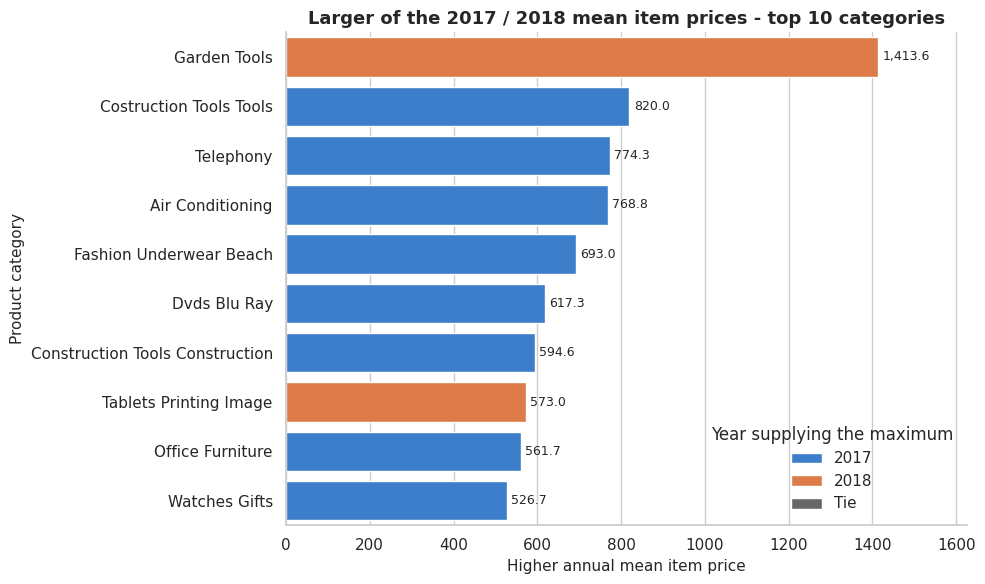

In [109]:
#Q29
yr = items[items['year'].isin([2017, 2018])].groupby(['category', 'year'])['price'].mean().unstack()
both = yr.dropna(subset=[2017, 2018]).copy()
both['max_mean_price'] = both[[2017, 2018]].max(axis=1)
both['source'] = np.where(np.isclose(both[2017], both[2018]), 'Tie', np.where(both[2017] > both[2018], '2017', '2018'))
top10 = both.nlargest(10, 'max_mean_price').reset_index()
top10['label'] = nice(top10['category'])
display(top10[['label', 2017, 2018, 'max_mean_price', 'source']])

HUE = {'2017': PAL[0], '2018': PAL[1], 'Tie': MUTED}
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top10, x='max_mean_price', y='label', hue='source', hue_order=list(HUE), palette=HUE,
            orient='h', dodge=False, errorbar=None, ax=ax)
for c in ax.containers:
    ax.bar_label(c, labels=[f'{b.get_width():,.1f}' if b.get_width() > 0 else '' for b in c], fontsize=9, padding=3)
ax.set_xlim(0, top10['max_mean_price'].max() * 1.15)
ax.set_title('Larger of the 2017 / 2018 mean item prices - top 10 categories')
ax.set_xlabel('Higher annual mean item price'); ax.set_ylabel('Product category')
ax.legend(title='Year supplying the maximum', loc='lower right')
plt.tight_layout(); plt.show()

Shares sum before rounding = 100.0000000000%


,share_%
SP,41.44
RJ,13.56
MG,11.84
RS,5.76
PR,4.89
Other,22.51


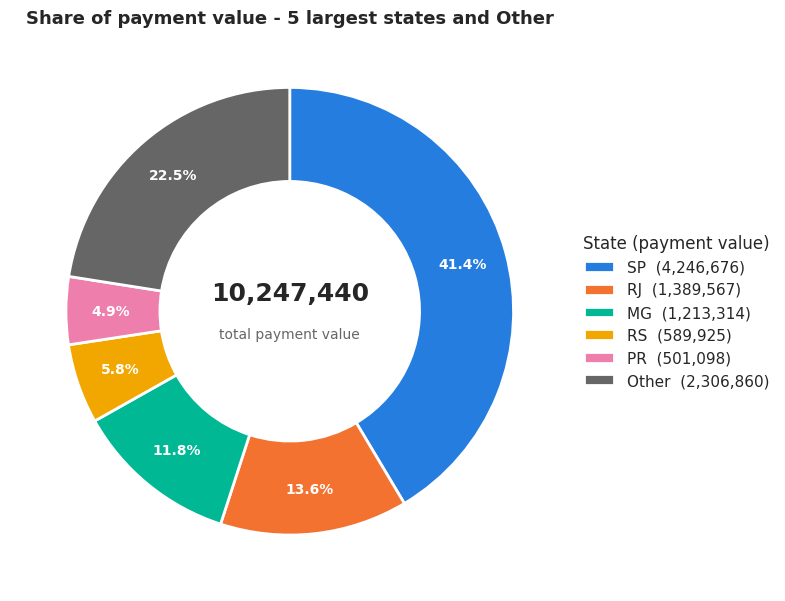

In [110]:
#Q30
order_pay = pay.groupby('order_id')['payment_value'].sum()
state_of = orders.set_index('order_id')['customer_state'].reindex(order_pay.index)
sp_ext    = order_pay.where(state_of == 'SP')
nonsp_ext = order_pay.where(state_of != 'SP')
recovered = sp_ext.combine_first(nonsp_ext).reindex(order_pay.index)

pd.testing.assert_series_equal(recovered, order_pay)
assert np.isclose(recovered.sum(), payments['payment_value'].sum())

by_state = recovered.groupby(state_of).sum().sort_values(ascending=False)
top5 = by_state.head(5)
donut = pd.concat([top5, pd.Series({'Other': by_state.iloc[5:].sum()})])
shares = donut / donut.sum()
assert np.isclose(shares.sum(), 1.0), 'shares must sum to 100% before rounding'
print(f'Shares sum before rounding = {shares.sum()*100:.10f}%')
display((shares * 100).round(2).to_frame('share_%'))

colors = PAL[:5] + [MUTED]
fig, ax = plt.subplots(figsize=(8, 8))
wedges, _, autotexts = ax.pie(donut, colors=colors, startangle=90, counterclock=False,
                              autopct='%1.1f%%', pctdistance=0.8,
                              wedgeprops={'width': 0.42, 'edgecolor': 'white', 'linewidth': 2},
                              textprops={'color': 'white', 'fontweight': 'bold', 'fontsize': 10})
ax.text(0, 0.05, f'{donut.sum():,.0f}', ha='center', fontsize=18, fontweight='bold')
ax.text(0, -0.12, 'total payment value', ha='center', fontsize=10, color=MUTED)
ax.legend(wedges, [f'{k}  ({v:,.0f})' for k, v in donut.items()], title='State (payment value)',
          loc='center left', bbox_to_anchor=(1.0, 0.5))
ax.set_title('Share of payment value - 5 largest states and Other')
plt.tight_layout(); plt.show()